# Comparación con el conjunto complementario

Este notebook desarrolla el objetivo específico 4 del proyecto: cuantificar el cambio en el desempeño al incorporar variables de sueño, funcionamiento global y uso de internet, comparando ambos conjuntos de variables bajo las mismas condiciones de evaluación. Responde a la pregunta complementaria de la formulación: cuánta información aportan los indicadores físicos frente a medidas de carácter psicológico, conductual o clínico.

La comparación parte de la configuración seleccionada en `03_busqueda_modelos.ipynb`: un modelo lineal regularizado (ElasticNet) en la formulación de regresión con umbrales. Los dos conjuntos de variables son:

- **Principal.** Reúne las variables demográficas, las físicas tabulares y el resumen de la actigrafía.
- **Complementario.** Agrega al principal tres variables: el puntaje T de la escala de alteraciones del sueño (SDS), el puntaje de funcionamiento global (CGAS) y las horas diarias de uso de computador e internet.

Ambos conjuntos se evalúan sobre los mismos 2.736 participantes, con las mismas particiones externas (cinco particiones estratificadas por SII, repetidas cinco veces) y la misma validación interna. La única diferencia entre las dos evaluaciones son las tres variables agregadas.

La hipótesis H4 de la formulación plantea que el conjunto complementario alcanza un QWK mayor que el principal. Su protocolo quedó registrado en la búsqueda de modelos, y la regla para concluir quedó fijada en el paquete del proyecto antes de evaluar el conjunto complementario.

El notebook se organiza así:

1. Datos, particiones y variables complementarias.
2. Protocolo de H4 y análisis descriptivos.
3. Evaluaciones del conjunto principal y del complementario.
4. Prueba de H4.
5. Desempeño por nivel y escenario de tamizaje.
6. Comparación por grupo de edad.
7. Configuraciones de los experimentos iniciales.
8. Tablas exportadas y conclusiones.

Todas las salidas son agregadas: ninguna tabla contiene filas por participante ni identificadores.

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from piu_severity.config import FIGURES_DIR, INTERIM_DATA_DIR, TABLES_DIR
from piu_severity.data.clean import clean_values
from piu_severity.data.load import list_actigraphy_ids, load_train
from piu_severity.evaluation.inference import (
    SEVERE_LEVEL,
    holm_adjust,
    participant_hit_rates,
)
from piu_severity.evaluation.metrics import (
    SII_LEVELS,
    UNDERESTIMATION_LEVELS,
    as_levels,
)
from piu_severity.evaluation.paired import (
    compare_participant_rates,
    participant_levels_referral_rates,
    participant_underestimation_rates,
)
from piu_severity.evaluation.persistence import (
    CACHE_VERSION,
    clear_pipeline_memory,
    evaluation_fields,
    run_configurations_cached,
    run_nested_cv_cached,
)
from piu_severity.evaluation.reporting import metric_summary
from piu_severity.evaluation.screening import (
    REFERRAL_LEVEL,
    level_referral_by_repeat,
    participant_bootstrap_screening,
    screening_by_repeat,
)
from piu_severity.evaluation.selection import (
    HOLM_FAMILIES,
    SELECTION_ALPHA,
    chosen_value_counts,
)
from piu_severity.evaluation.subgroups import (
    AGE_GROUPS,
    age_group,
    subgroup_metrics_by_repeat,
    subgroup_summary,
)
from piu_severity.evaluation.superiority import (
    SUPERIORITY_CONFIDENCE,
    superiority_conclusion,
    superiority_lower_bound,
)
from piu_severity.evaluation.validation import (
    N_OUTER_REPEATS,
    N_OUTER_SPLITS,
    outer_splits,
    paired_differences,
    summarize_by_repeat,
    summarize_paired,
)
from piu_severity.features.actigraphy import load_actigraphy_summary
from piu_severity.features.build import build_analytic_dataset
from piu_severity.features.groups import TARGET_COLUMN, experiment_feature_sets
from piu_severity.models.pipelines import (
    available_workers,
    make_boosting_search,
    make_logistic_search,
)
from piu_severity.models.registry import check_result, load_record, rebuild_task
from piu_severity.visualization.figures import save_figure

In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
sns.set_theme(style="whitegrid")

# Figuras y tablas del notebook, en carpetas con su nombre.
FIGURAS = FIGURES_DIR / "05_comparacion_complementario"
TABLAS = TABLES_DIR / "05_comparacion_complementario"
# Caché de evaluaciones del notebook 03: guarda las evaluaciones del conjunto
# principal registradas en la búsqueda. Está bajo data/interim, que git ignora,
# porque contiene predicciones por participante.
CARPETA_CACHE_03 = INTERIM_DATA_DIR / "03_busqueda_modelos" / "cache"
# Caché propio de este notebook, para las evaluaciones nuevas.
CARPETA_NOTEBOOK = INTERIM_DATA_DIR / "05_comparacion_complementario"
CARPETA_CACHE = CARPETA_NOTEBOOK / "cache"
# Caché de Pipeline(memory=...): evita reajustar el preprocesamiento entre
# candidatos de la validación interna; se libera al final.
CARPETA_MEMORIA = CARPETA_NOTEBOOK / "pipeline_memory" / f"v{CACHE_VERSION}"

# Con True se vuelven a ajustar las evaluaciones aunque existan en el caché.
RECALCULAR = False
# Procesos en paralelo: todos los núcleos menos dos.
N_PROCESOS = available_workers("linear", os.cpu_count())

NIVELES_SII = {0: "ninguno", 1: "leve", 2: "moderado", 3: "severo"}
NOMBRES_CONJUNTOS = {
    "reference": "referencia",
    "main": "principal",
    "complementary": "complementario",
}
# Los dos análisis del protocolo de H4.
NOMBRES_ANALISIS = {
    "fixed": "tratamiento fijo",
    "chosen": "tratamiento elegido en cada partición",
}
# Variables que el conjunto complementario agrega al principal.
VARIABLES_COMPLEMENTARIAS = {
    "SDS-SDS_Total_T": "alteraciones del sueño (SDS, puntaje T)",
    "CGAS-CGAS_Score": "funcionamiento global (CGAS)",
    "PreInt_EduHx-computerinternet_hoursday": "horas diarias de computador e internet",
}

## 1. Datos, particiones y variables complementarias

Esta sección reconstruye el conjunto analítico y las particiones externas con las mismas funciones del paquete que usó la búsqueda de modelos. Primero verifica que reproducen las cifras de la Entrega 2: 2.736 participantes con SII, 34 de ellos severos, 36 predictores en el conjunto principal y 39 en el complementario. Luego comprueba que los dos conjuntos difieren solo en las tres variables complementarias.

Para cada variable complementaria se reporta la proporción de participantes que la tienen registrada, en total y por nivel de SII. Los participantes sin el dato permanecen en el análisis: como en el resto de las variables, sus valores se imputan dentro del flujo de procesamiento, ajustado solo con la partición de entrenamiento.

Dos de las tres variables provienen de cuestionarios que responden los padres: la escala de alteraciones del sueño y las horas de uso de computador e internet. El CGAS, en cambio, es una valoración del clínico. Como el SII también se deriva del reporte de los padres, parte de la información que aportan esas variables puede compartir informante con la variable objetivo, y en las horas de uso, también el comportamiento que se mide.

In [3]:
# Conjunto analítico: participantes con SII, con las reglas de limpieza y el
# resumen de actigrafía del análisis exploratorio.
train = load_train()
etiquetados = train[train[TARGET_COLUMN].notna()].reset_index(drop=True)
analitico = build_analytic_dataset(
    clean_values(etiquetados), load_actigraphy_summary(list_actigraphy_ids())
)
y = as_levels(analitico[TARGET_COLUMN])
conjuntos = experiment_feature_sets(analitico.columns)

# Cifras de la Entrega 2 que el conjunto debe reproducir.
N_ETIQUETADOS_ENTREGA_2 = 2_736
N_SEVEROS_ENTREGA_2 = 34
N_PREDICTORES_ENTREGA_2 = {"main": 36, "complementary": 39}
assert len(analitico) == N_ETIQUETADOS_ENTREGA_2
assert analitico["id"].is_unique
assert int((y == SEVERE_LEVEL).sum()) == N_SEVEROS_ENTREGA_2
assert {c: len(conjuntos[c]) for c in N_PREDICTORES_ENTREGA_2} == (
    N_PREDICTORES_ENTREGA_2
)

# El complementario es el principal más las tres variables complementarias.
agregadas = [c for c in conjuntos["complementary"] if c not in conjuntos["main"]]
assert set(conjuntos["main"]) <= set(conjuntos["complementary"])
assert set(agregadas) == set(VARIABLES_COMPLEMENTARIAS)

# Particiones externas: cinco estratificadas por SII, repetidas cinco veces con
# la semilla 42 + r en la repetición r; son las mismas de la búsqueda.
particiones = outer_splits(y)
assert len(particiones) == N_OUTER_SPLITS * N_OUTER_REPEATS

# Proporción de participantes con cada variable complementaria registrada, en
# total y por nivel de SII.
registradas = analitico[list(VARIABLES_COMPLEMENTARIAS)].notna()
cobertura = pd.concat(
    {
        "todos": registradas.mean(),
        **{NIVELES_SII[nivel]: registradas[y == nivel].mean() for nivel in SII_LEVELS},
    },
    axis="columns",
)
cobertura = (100 * cobertura).rename(index=VARIABLES_COMPLEMENTARIAS)
cobertura.index.name = "variable"
cobertura.columns.name = "participantes con dato (%)"
cobertura.round(1)

participantes con dato (%),todos,ninguno,leve,moderado,severo
variable,,,,,
"alteraciones del sueño (SDS, puntaje T)",92.3,92.2,93.2,91.3,88.2
funcionamiento global (CGAS),85.6,85.3,86.6,85.2,85.3
horas diarias de computador e internet,97.0,96.7,97.9,96.0,100.0


### Conclusión

- **Conjunto analítico.** Reproduce las cifras de la Entrega 2: 2.736 participantes con SII, 34 de ellos severos, 36 predictores en el conjunto principal y 39 en el complementario. Los dos conjuntos difieren solo en las tres variables complementarias.
- **Cobertura.** Las tres variables están registradas en la mayoría de los participantes: las horas de uso de computador e internet en el 97,0 %, el puntaje de alteraciones del sueño en el 92,3 % y el de funcionamiento global en el 85,6 %. La cobertura varía poco entre niveles de SII. La mayor diferencia está en los severos, que tienen el puntaje de sueño en el 88,2 % de los casos y las horas de uso en el 100 %.

Como la cobertura es alta y similar entre niveles, la imputación afecta a pocos participantes en estas variables, y no favorece a ningún nivel de SII.

## 2. Protocolo de H4 y análisis descriptivos

El protocolo de H4 quedó registrado en la búsqueda de modelos, antes de evaluar el conjunto complementario, y esta sección lo lee del registro:

- **Prueba.** En cada una de las 25 particiones externas se calcula la diferencia de QWK entre el complementario y el principal. Las particiones comparten participantes y datos de entrenamiento, así que sus diferencias no son independientes. Por eso se usa la prueba t corregida de Nadeau y Bengio, unilateral, con un nivel de significancia de 0,05. H4 forma su propia familia de Holm, con una sola prueba, de modo que el ajuste no cambia el valor p. La formulación ajustaba juntas las pruebas pareadas de H2 a H4; la familia propia de H4 se definió al registrar el protocolo.
- **Análisis principal: tratamiento fijo.** El tratamiento de los faltantes y el exponente de ponderación α se fijan en los valores más elegidos por la configuración seleccionada (imputación iterativa y α = 0,5), y la validación interna elige solo los hiperparámetros del modelo. Así, la diferencia entre los dos conjuntos refleja las variables y no un cambio de tratamiento. La formulación habla de entrenar "la configuración seleccionada" con el conjunto complementario; el tratamiento fijo es el mismo que se usó para H2 y H3.
- **Sensibilidad: tratamiento elegido en cada partición.** Es la configuración seleccionada tal como se evaluó: la validación interna elige también el tratamiento.
- **Comparador.** En el análisis principal, el principal es su evaluación con tratamiento fijo, cuyo QWK medio registrado es 0,368. La evaluación con el tratamiento elegido en cada partición, que es la que se analizó como modelo seleccionado, tiene un QWK de 0,365. Los dos valores se muestran en la sección 3; H4 compara cada evaluación del principal con la del complementario en el mismo análisis.
- **Conclusión y magnitud.** H4 se sostiene si el valor p ajustado del análisis principal es menor que 0,05. La sensibilidad la confirma si llega a la misma conclusión. Como magnitud se reporta la cota inferior unilateral del 95 % de la diferencia media, sin probarla contra la diferencia mínima relevante.

Además, se fijan antes de calcularlos tres análisis descriptivos, que no forman parte de ninguna familia de pruebas:

- **Desempeño por nivel y tamizaje, pareado.** Los dos conjuntos predicen a los mismos participantes. Por eso, el recall por nivel, la tasa de subestimación y las métricas del tamizaje se comparan por participante: cada participante tiene una tasa en cada conjunto, y se reporta la diferencia media con su intervalo del 95 % por remuestreo de participantes y el valor p de una prueba de cambio de signo.
- **Por grupo de edad.** El principal y el complementario se comparan dentro de cada grupo de edad (5 a 12, 13 a 17 y 18 a 22 años), para ver si las variables complementarias distinguen a participantes de una misma edad.
- **Configuraciones de los experimentos iniciales.** Se recalculan las dos configuraciones de la Entrega 2 (regresión logística y gradient boosting en la formulación multiclase, con una búsqueda reducida de hiperparámetros) con los dos conjuntos. Así se verifica la mejora que reportó la Entrega 2 y se comparan sus puntos de operación del tamizaje con los del modelo seleccionado.

In [4]:
# Protocolo de H4 registrado en la búsqueda de modelos.
registro = load_record()
protocolo = registro["h4_protocol"]


def entrada_registro(ruta: str) -> dict:
    """Entrada del registro indicada con una ruta del tipo «sección.clave»."""
    entrada = registro
    for clave in ruta.split("."):
        entrada = entrada[clave]
    return entrada


assert protocolo["hypothesis"] == "H4"
assert HOLM_FAMILIES[protocolo["holm_family"]] == ("H4",)
assert protocolo["feature_set"] == "complementary"
assert protocolo["compared_with"] == "main"
assert protocolo["alpha"] == SELECTION_ALPHA
RUTAS_ANALISIS = {
    "fixed": protocolo["main_analysis"]["base_evaluation"],
    "chosen": protocolo["sensitivity"]["base_evaluation"],
}
assert RUTAS_ANALISIS == {
    "fixed": "fixed_treatment_evaluations.main",
    "chosen": "selected.search",
}
entradas_principal = {
    analisis: entrada_registro(ruta) for analisis, ruta in RUTAS_ANALISIS.items()
}
# El tratamiento fijo es el registrado para H2 y H3.
assert (
    entradas_principal["fixed"]["config"]["fixed_params"] == registro["fixed_treatment"]
)

pd.Series(
    {
        "hipótesis": "el conjunto complementario alcanza un QWK mayor que el principal",
        "prueba": "t corregida de Nadeau y Bengio, unilateral",
        "nivel de significancia": protocolo["alpha"],
        "familia de Holm": ", ".join(HOLM_FAMILIES[protocolo["holm_family"]]),
        "análisis principal": NOMBRES_ANALISIS["fixed"],
        "sensibilidad": NOMBRES_ANALISIS["chosen"],
        "tratamiento fijo": ", ".join(
            f"{k} = {v}" for k, v in registro["fixed_treatment"].items()
        ),
        "confianza de la cota inferior": SUPERIORITY_CONFIDENCE,
    },
    name="protocolo de H4",
).to_frame()

,protocolo de H4
hipótesis,el conjunto complementario alcanza un QWK mayor que el principal
prueba,"t corregida de Nadeau y Bengio, unilateral"
nivel de significancia,0.05
familia de Holm,H4
análisis principal,tratamiento fijo
sensibilidad,tratamiento elegido en cada partición
tratamiento fijo,"model__weight_power = 0.5, preprocess__strategy = iterative"
confianza de la cota inferior,0.95


### Conclusión

El protocolo del registro coincide con el descrito: H4 es la única prueba de su familia de Holm, se prueba con un nivel de significancia de 0,05, y su análisis principal usa la evaluación del principal con el mismo tratamiento fijo de H2 y H3 (imputación iterativa y α = 0,5). La regla de conclusión y la cota inferior quedaron fijadas en el paquete antes de evaluar el conjunto complementario, igual que los tres análisis descriptivos.

## 3. Evaluaciones del conjunto principal y del complementario

Las dos evaluaciones del conjunto principal se reconstruyen a partir del registro, con la misma firma de la búsqueda: datos, particiones, grilla, semillas y versiones de las bibliotecas. Se cargan del caché de evaluaciones de la búsqueda, y se comprueba que reproducen el QWK medio registrado. Las del conjunto complementario usan exactamente la misma configuración, cambiando solo el conjunto de predictores, y se ajustan en este notebook sobre las mismas particiones.

Para cada evaluación se reportan su QWK medio y la desviación entre repeticiones. En la sensibilidad, se reporta además qué tratamiento eligió la validación interna del complementario en cada partición.

In [5]:
# Evaluaciones del conjunto principal: se reconstruyen con la firma del registro
# y se cargan del caché de la búsqueda.
tareas_principal = {
    analisis: rebuild_task(
        entrada,
        analitico[conjuntos["main"]],
        y,
        particiones,
        memory=str(CARPETA_MEMORIA),
    )
    for analisis, entrada in entradas_principal.items()
}
# Evaluaciones del conjunto complementario: la misma configuración con otro
# conjunto de predictores, en el caché de este notebook.
tareas_complementario = {
    analisis: rebuild_task(
        entrada,
        analitico[conjuntos["complementary"]],
        y,
        particiones,
        feature_set="complementary",
        memory=str(CARPETA_MEMORIA),
    )
    for analisis, entrada in entradas_principal.items()
}

inicio = time.perf_counter()
cargados_principal = run_configurations_cached(
    list(tareas_principal.values()),
    cache_dir=CARPETA_CACHE_03,
    n_jobs=N_PROCESOS,
    force=RECALCULAR,
)
cargados_complementario = run_configurations_cached(
    list(tareas_complementario.values()),
    cache_dir=CARPETA_CACHE,
    n_jobs=N_PROCESOS,
    force=RECALCULAR,
    verbose=5,
)
print(f"Minutos en esta ejecución: {(time.perf_counter() - inicio) / 60:.1f}")

resultados = {
    ("main", analisis): cargados_principal[tarea.name]
    for analisis, tarea in tareas_principal.items()
}
resultados |= {
    ("complementary", analisis): cargados_complementario[tarea.name]
    for analisis, tarea in tareas_complementario.items()
}
# Las evaluaciones del principal reproducen el QWK registrado, y todas cubren las
# mismas particiones y a los mismos participantes.
for analisis, entrada in entradas_principal.items():
    check_result(resultados[("main", analisis)], entrada)
for resultado in resultados.values():
    assert len(resultado.folds) == len(particiones)
    assert np.array_equal(
        resultado.predictions["y_true"].to_numpy(),
        y[resultado.predictions["position"].to_numpy()],
    )

filas = {}
for (conjunto, analisis), resultado in resultados.items():
    qwk_repeticion = summarize_by_repeat(resultado.folds, resultado.predictions)["qwk"]
    conteo = resultado.counts()
    filas[(NOMBRES_ANALISIS[analisis], NOMBRES_CONJUNTOS[conjunto])] = {
        "QWK medio": resultado.folds["qwk"].mean(),
        "desviación entre repeticiones": qwk_repeticion.std(),
        "particiones cargadas": conteo["loaded"],
        "particiones ajustadas": conteo["computed"],
    }
evaluaciones = pd.DataFrame.from_dict(filas, orient="index").rename_axis(
    ["análisis", "conjunto"]
)
evaluaciones.round(4)

Minutos en esta ejecución: 0.0


[Parallel(n_jobs=13)]: Using backend LokyBackend with 13 concurrent workers.


,,QWK medio,desviación entre repeticiones,particiones cargadas,particiones ajustadas
análisis,conjunto,,,,
tratamiento fijo,principal,0.3685,0.0047,25,0
tratamiento elegido en cada partición,principal,0.3652,0.0074,25,0
tratamiento fijo,complementario,0.4413,0.0040,25,0
tratamiento elegido en cada partición,complementario,0.4406,0.0039,25,0


In [6]:
# Tratamiento elegido por la validación interna en cada partición externa, en la
# sensibilidad: estrategia de faltantes y exponente de ponderación α.
NOMBRES_ESTRATEGIAS = {"iterative": "iterativa", "simple": "simple con indicadores"}
filas = {}
for conjunto in ("main", "complementary"):
    parametros = list(resultados[(conjunto, "chosen")].folds["best_params"])
    estrategias = chosen_value_counts(parametros, "preprocess__strategy")
    exponentes = chosen_value_counts(parametros, "model__weight_power")
    filas[NOMBRES_CONJUNTOS[conjunto]] = {
        **{
            f"estrategia {NOMBRES_ESTRATEGIAS[e]}": int(n)
            for e, n in estrategias.items()
        },
        **{f"α = {a:g}": int(n) for a, n in exponentes.items()},
    }
tratamiento_elegido = (
    pd.DataFrame.from_dict(filas, orient="index")
    .fillna(0)
    .astype(int)
    .rename_axis("conjunto")
)
tratamiento_elegido

,estrategia iterativa,estrategia simple con indicadores,α = 0.5,α = 1
conjunto,,,,
principal,20,5,25,0
complementario,15,10,24,1


### Conclusión

- **Conjunto principal.** Las dos evaluaciones se cargan del caché de la búsqueda sin volver a ajustarse y reproducen el QWK registrado: 0,3685 con tratamiento fijo y 0,3652 con el tratamiento elegido en cada partición. La diferencia entre ambas, de 0,003, viene solo del tratamiento de los faltantes. Por eso H4 compara cada evaluación del principal con la del complementario en el mismo análisis, y no mezcla una con otra.
- **Conjunto complementario.** Sus evaluaciones se ajustan en este notebook y quedan en su caché. Su QWK medio es 0,4413 con tratamiento fijo y 0,4406 con el tratamiento elegido en cada partición, con desviaciones entre repeticiones de 0,004 en ambos análisis.
- **Tratamiento elegido.** Con el conjunto complementario, la validación interna eligió la imputación simple con indicadores en 10 de las 25 particiones, frente a 5 con el principal. El exponente de ponderación α fue 0,5 en 24 particiones y 1 en una sola.

Con los dos tratamientos, el QWK medio del complementario es mayor que el del principal en unos 0,07 puntos. La sección 4 pone a prueba esa diferencia partición por partición.

## 4. Prueba de H4

La prueba sigue el protocolo de la sección 2. En cada análisis, para cada una de las 25 particiones externas, se calcula la diferencia de QWK entre el complementario y el principal, y su media se prueba con la prueba t corregida de Nadeau y Bengio, unilateral:

$$
t = \frac{\bar{d}}{\sqrt{\left(\frac{1}{J} + \frac{n_{\text{eval}}}{n_{\text{entr}}}\right) s_d^2}},
$$

donde $\bar{d}$ y $s_d$ son la media y la desviación estándar de las $J = 25$ diferencias, y $n_{\text{eval}}/n_{\text{entr}}$ es la razón entre el tamaño de las particiones de evaluación y de entrenamiento. El término $n_{\text{eval}}/n_{\text{entr}}$ corrige la varianza, porque las particiones comparten participantes. El valor p se ajusta con Holm dentro de la familia de H4, y la cota inferior unilateral del 95 % de la diferencia media se reporta como magnitud. La conclusión se obtiene con la regla fijada en el paquete.

In [7]:
# H4: diferencia de QWK complementario − principal en cada partición externa, en
# los dos análisis del protocolo, con la prueba t corregida unilateral, el ajuste
# de Holm dentro de la familia de H4 y la cota inferior de la diferencia media.
diferencias_h4 = {}
filas = {}
for analisis in NOMBRES_ANALISIS:
    diferencias = paired_differences(
        resultados[("complementary", analisis)].folds,
        resultados[("main", analisis)].folds,
    )
    diferencias_h4[analisis] = diferencias
    prueba = summarize_paired(diferencias)
    cota = superiority_lower_bound(diferencias)
    filas[analisis] = {
        "QWK principal": diferencias["qwk_b"].mean(),
        "QWK complementario": diferencias["qwk_a"].mean(),
        "diferencia media de QWK": prueba["mean_difference"],
        "desviación de la diferencia": prueba["std_difference"],
        "particiones con mejora": prueba["folds_improved"],
        "t corregido": prueba["corrected_t"],
        "valor p (unilateral)": prueba["p_value_one_sided"],
        # H4 es la única prueba de su familia de Holm en cada análisis.
        "valor p ajustado (Holm)": holm_adjust({"H4": prueba["p_value_one_sided"]})[
            "H4"
        ],
        f"cota inferior unilateral del {SUPERIORITY_CONFIDENCE:.0%}": cota[
            "lower_bound"
        ],
    }
pruebas_h4 = pd.DataFrame.from_dict(filas, orient="index")

# Regla fijada antes de evaluar el complementario: la conclusión sale del análisis
# principal, y la sensibilidad la confirma si llega a la misma conclusión.
conclusion_h4 = superiority_conclusion(
    pruebas_h4.loc["fixed", "valor p ajustado (Holm)"],
    pruebas_h4.loc["chosen", "valor p ajustado (Holm)"],
)
print(
    "H4 se sostiene en el análisis principal: "
    f"{'sí' if conclusion_h4['supported'] else 'no'}"
)
print(
    "La sensibilidad llega a la misma conclusión: "
    f"{'sí' if conclusion_h4['confirmed'] else 'no'}"
)
pruebas_h4.rename(index=NOMBRES_ANALISIS).rename_axis("análisis").round(4)

H4 se sostiene en el análisis principal: sí
La sensibilidad llega a la misma conclusión: sí


,QWK principal,QWK complementario,diferencia media de QWK,desviación de la diferencia,particiones con mejora,t corregido,valor p (unilateral),valor p ajustado (Holm),cota inferior unilateral del 95%
análisis,,,,,,,,,
tratamiento fijo,0.3685,0.4413,0.0727,0.0353,25,3.8286,0.0004,0.0004,0.0402
tratamiento elegido en cada partición,0.3652,0.4406,0.0755,0.0373,25,3.7558,0.0005,0.0005,0.0411


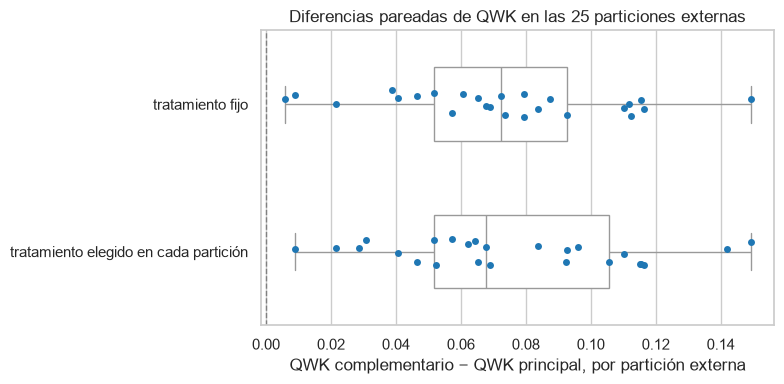

In [8]:
# Diferencias de QWK en las 25 particiones externas de cada análisis.
largo = pd.concat(
    {
        NOMBRES_ANALISIS[analisis]: diferencias["difference"]
        for analisis, diferencias in diferencias_h4.items()
    },
    names=["análisis", "partición"],
).reset_index(name="diferencia de QWK")
fig, eje = plt.subplots(figsize=(8, 4))
sns.boxplot(
    data=largo,
    x="diferencia de QWK",
    y="análisis",
    color="white",
    width=0.5,
    showfliers=False,
    ax=eje,
)
sns.stripplot(
    data=largo, x="diferencia de QWK", y="análisis", color="tab:blue", size=5, ax=eje
)
eje.axvline(0, color="gray", linestyle="--", linewidth=1)
eje.set_xlabel("QWK complementario − QWK principal, por partición externa")
eje.set_ylabel("")
eje.set_title("Diferencias pareadas de QWK en las 25 particiones externas")
fig.tight_layout()
save_figure(fig, "diferencias_h4", FIGURAS)
plt.show()

### Conclusión

- **H4 se sostiene.** Con tratamiento fijo, el QWK medio sube de 0,3685 con el conjunto principal a 0,4413 con el complementario. La diferencia media es 0,073, con una desviación de 0,035, y es positiva en las 25 particiones externas. El t corregido es 3,83 y el valor p unilateral, 0,0004, igual después del ajuste de Holm.
- **La sensibilidad la confirma.** Con el tratamiento elegido en cada partición, el QWK sube de 0,3652 a 0,4406. La diferencia media es 0,076, positiva en las 25 particiones, con un t corregido de 3,76 y un valor p de 0,0005.
- **Magnitud.**
  - La cota inferior unilateral del 95 % es 0,040 en el análisis principal y 0,041 en la sensibilidad: la mejora media es de al menos 0,04 puntos de QWK.
  - La diferencia media equivale a un aumento de alrededor del 20 % sobre el QWK del principal.
  - En la escala de Landis y Koch, el acuerdo pasa de aceptable a moderado, cerca del límite inferior de esa categoría.
  - Como referencia descriptiva, la cota supera la diferencia mínima relevante de 0,03 usada en H2 y H3, aunque esa comparación no forma parte del protocolo de H4.
- **Variabilidad entre particiones.** Las diferencias son positivas en todas las particiones, pero su tamaño varía mucho: desde menos de 0,01 hasta unos 0,15. Por eso la desviación de la diferencia es grande frente a su media, y el valor p, aunque muy pequeño, no lo es tanto como sugeriría una mejora en las 25 particiones.

Tres variables de sueño, funcionamiento global y uso de internet aumentan el acuerdo más que las 33 variables físicas sobre la referencia demográfica, cuyo aporte resultó despreciable en la búsqueda de modelos (H2). La comparación tiene dos límites:

- La configuración se eligió con el conjunto principal, así que el complementario se evalúa con un protocolo que no se ajustó para él. Si eso favorece a alguno de los dos conjuntos, es al principal.
- Dos de las tres variables las reportan los padres, igual que el SII, y las horas de uso de internet miden en parte el mismo comportamiento. Parte de la mejora puede deberse a ese solapamiento y no solo a información nueva.

La sección 5 examina si la mejora del QWK cambia los errores por nivel y el escenario de tamizaje.

## 5. Desempeño por nivel y escenario de tamizaje

Un QWK mayor no implica que mejoren los niveles que importan en un tamizaje. Esta sección compara el principal y el complementario nivel por nivel y en el escenario de remisión de todo participante con nivel estimado moderado o severo, con el análisis pareado fijado en la sección 2:

- **Tasas por participante.** Cada participante tiene, en cada conjunto, una tasa por métrica, que es la proporción de repeticiones en que ocurre el evento:
  - para el recall de un nivel, que se le asigne su nivel real;
  - para la subestimación, que reciba un nivel inferior;
  - para el recall del tamizaje, la proporción de severos remitidos y la proporción remitida, que se le remita;
  - para la especificidad, que no se le remita si no tiene uso moderado o severo.

  La media de esas tasas es la métrica promediada entre repeticiones.
- **Diferencia pareada.** Para cada métrica se reporta la diferencia media complementario − principal, con su intervalo del 95 % por remuestreo de participantes (10.000 remuestreos) y el valor p bilateral de una prueba de cambio de signo. Una diferencia positiva es favorable al complementario en los recall y la especificidad. En la subestimación, la favorable es la negativa, y en la proporción remitida, una diferencia positiva es un costo.
- **Alcance.** Son comparaciones descriptivas, fuera de la familia de H4. Se calculan nueve métricas en dos análisis, así que un valor p aislado no se interpreta como una conclusión. El nivel severo tiene 34 casos, y sus intervalos son amplios.
- **Escenario de tamizaje.** Las cuatro métricas del escenario se reportan para cada conjunto, con su desviación entre repeticiones y su intervalo por remuestreo de participantes. El valor predictivo positivo no tiene una tasa por participante, así que se compara solo con esta tabla.

In [ ]:
# Tasas por participante de cada métrica: la media de las tasas de los
# participantes de un nivel es la métrica promediada entre repeticiones.
NIVELES_NEGATIVOS = tuple(nivel for nivel in SII_LEVELS if nivel < REFERRAL_LEVEL)
TASAS_POR_PARTICIPANTE = {
    **{
        f"recall {NIVELES_SII[nivel]}": (
            lambda p, nivel=nivel: participant_hit_rates(p, nivel)
        )
        for nivel in SII_LEVELS
    },
    "subestimación moderado o severo": participant_underestimation_rates,
    "recall del tamizaje": lambda p: participant_levels_referral_rates(
        p, UNDERESTIMATION_LEVELS
    ),
    "especificidad del tamizaje": lambda p: (
        1 - participant_levels_referral_rates(p, NIVELES_NEGATIVOS)
    ),
    "proporción remitida": lambda p: participant_levels_referral_rates(p, SII_LEVELS),
    "proporción de severos remitidos": lambda p: participant_levels_referral_rates(
        p, (SEVERE_LEVEL,)
    ),
}

# Comparación pareada complementario − principal en cada análisis.
filas = {}
for analisis, nombre_analisis in NOMBRES_ANALISIS.items():
    principal = resultados[("main", analisis)].predictions
    complementario = resultados[("complementary", analisis)].predictions
    # Las tasas reproducen las métricas del tamizaje promediadas entre repeticiones.
    assert np.isclose(
        TASAS_POR_PARTICIPANTE["recall del tamizaje"](principal).mean(),
        screening_by_repeat(principal)["recall"].mean(),
    )
    for metrica, tasas in TASAS_POR_PARTICIPANTE.items():
        comparacion = compare_participant_rates(tasas(complementario), tasas(principal))
        filas[(nombre_analisis, metrica)] = {
            "principal": comparacion["mean_b"],
            "complementario": comparacion["mean_a"],
            "diferencia": comparacion["difference"],
            "intervalo 95 % inferior": comparacion["interval_low"],
            "intervalo 95 % superior": comparacion["interval_high"],
            "valor p (cambio de signo)": comparacion["p_value_two_sided"],
            "participantes": comparacion["participants"],
            "participantes con distinta tasa": comparacion["participants_differing"],
        }
comparacion_pareada = pd.DataFrame.from_dict(filas, orient="index").rename_axis(
    ["análisis", "métrica"]
)
comparacion_pareada.round(3)

principal  \
análisis                              métrica                                      
tratamiento fijo                      recall ninguno                       0.654   
                                      recall leve                          0.390   
                                      recall moderado                      0.341   
                                      recall severo                        0.000   
                                      subestimación moderado o severo      0.687   
                                      recall del tamizaje                  0.371   
                                      especificidad del tamizaje           0.861   
                                      proporción remitida                  0.174   
                                      proporción de severos remitidos      0.706   
tratamiento elegido en cada partición recall ninguno                       0.658   
                                      recall leve                          0.384   
                                      recall moderado                      0.346   
                                      recall severo                        0.000   
                                      subestimación moderado o severo      0.683   
                                      recall del tamizaje                  0.375   
                                      especificidad del tamizaje           0.860   
                                      proporción remitida                  0.176   
                                      proporción de severos remitidos      0.706   

                                                                       complementario  \
análisis                              métrica                                           
tratamiento fijo                      recall ninguno                            0.681   
                                      recall leve                               0.378   
                                      recall moderado                           0.441   
                                      recall severo                             0.118   
                                      subestimación moderado o severo           0.564   
                                      recall del tamizaje                       0.497   
                                      especificidad del tamizaje                0.856   
                                      proporción remitida                       0.198   
                                      proporción de severos remitidos           0.853   
tratamiento elegido en cada partición recall ninguno                            0.685   
                                      recall leve                               0.377   
                                      recall moderado                           0.421   
                                      recall severo                             0.153   
                                      subestimación moderado o severo           0.577   
                                      recall del tamizaje                       0.480   
                                      especificidad del tamizaje                0.860   
                                      proporción remitida                       0.191   
                                      proporción de severos remitidos           0.835   

                                                                       diferencia  \
análisis                              métrica                                       
tratamiento fijo                      recall ninguno                        0.028   
                                      recall leve                          -0.012   
                                      recall moderado                       0.099   
                                      recall severo                         0.118   
                                      subestimación moderado o severo      -0.123   
              

In [ ]:
# Las cuatro métricas del escenario de tamizaje de cada conjunto, con su
# desviación entre repeticiones y su intervalo por remuestreo de participantes.
ETIQUETAS_TAMIZAJE = {
    "recall": "recall",
    "specificity": "especificidad",
    "ppv": "valor predictivo positivo",
    "referred_share": "proporción remitida",
}
tablas = {}
for analisis, nombre_analisis in NOMBRES_ANALISIS.items():
    for conjunto in ("main", "complementary"):
        predicciones_conjunto = resultados[(conjunto, analisis)].predictions
        bootstrap = participant_bootstrap_screening(predicciones_conjunto)
        tablas[(nombre_analisis, NOMBRES_CONJUNTOS[conjunto])] = metric_summary(
            screening_by_repeat(predicciones_conjunto),
            intervals={
                metrica: tuple(
                    bootstrap.loc[metrica, ["interval_low", "interval_high"]]
                )
                for metrica in bootstrap.index
            },
        )[["mean", "std_between_repeats", "interval_low", "interval_high"]]
tamizaje_conjuntos = (
    pd.concat(tablas, names=["análisis", "conjunto", "métrica"])
    .rename(index=ETIQUETAS_TAMIZAJE, level="métrica")
    .rename(
        columns={
            "mean": "media",
            "std_between_repeats": "desviación entre repeticiones",
            "interval_low": "intervalo 95 % inferior",
            "interval_high": "intervalo 95 % superior",
        }
    )
)
tamizaje_conjuntos.round(3)

media  \
análisis                              conjunto       métrica                            
tratamiento fijo                      principal      recall                     0.371   
                                                     especificidad              0.861   
                                                     valor predictivo positivo  0.322   
                                                     proporción remitida        0.174   
                                      complementario recall                     0.497   
                                                     especificidad              0.856   
                                                     valor predictivo positivo  0.379   
                                                     proporción remitida        0.198   
tratamiento elegido en cada partición principal      recall                     0.375   
                                                     especificidad              0.860   
                                                     valor predictivo positivo  0.323   
                                                     proporción remitida        0.176   
                                      complementario recall                     0.480   
                                                     especificidad              0.860   
                                                     valor predictivo positivo  0.379   
                                                     proporción remitida        0.191   

                                                                                desviación entre repeticiones  \
análisis                              conjunto       métrica                                                    
tratamiento fijo                      principal      recall                                             0.053   
                                                     especificidad                                      0.025   
                                                     valor predictivo positivo                          0.012   
                                                     proporción remitida                                0.029   
                                      complementario recall                                             0.023   
                                                     especificidad                                      0.011   
                                                     valor predictivo positivo                          0.009   
                                                     proporción remitida                                0.013   
tratamiento elegido en cada partición principal      recall                                             0.052   
                                                     especificidad                                      0.025   
                                                     valor predictivo positivo                          0.013   
                                                     proporción remitida                                0.029   
                                      complementario recall                                             0.020   
                                                     especificidad                                      0.011   
                                                     valor predictivo positivo                          0.013   
                                                     proporción remitida                                0.012   

                                                                                intervalo 95 % inferior  \
análisis                              conjunto       métrica                                              
tratamiento fijo                      principal      recall                                       0.330   
                                                     especificidad                                0.848   
              

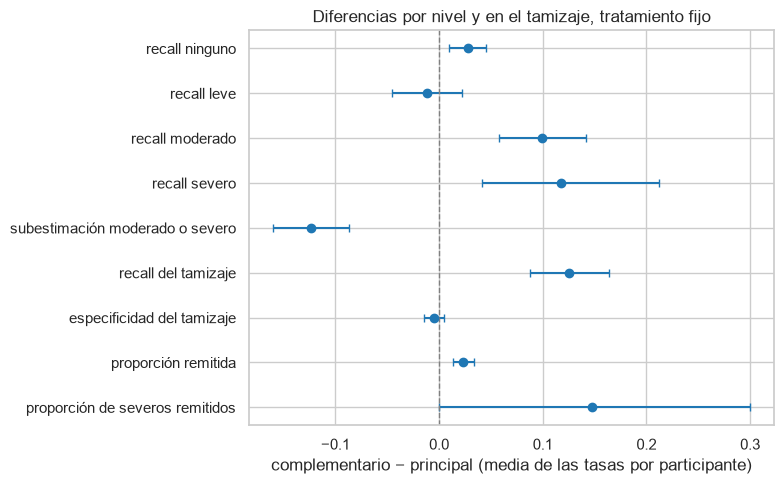

In [11]:
# Diferencias pareadas del análisis principal (tratamiento fijo), con su
# intervalo del 95 % por remuestreo de participantes.
diferencias_nivel = comparacion_pareada.loc[NOMBRES_ANALISIS["fixed"]]
fig, eje = plt.subplots(figsize=(8, 5))
posiciones_y = np.arange(len(diferencias_nivel))[::-1]
eje.errorbar(
    diferencias_nivel["diferencia"],
    posiciones_y,
    xerr=[
        diferencias_nivel["diferencia"] - diferencias_nivel["intervalo 95 % inferior"],
        diferencias_nivel["intervalo 95 % superior"] - diferencias_nivel["diferencia"],
    ],
    fmt="o",
    color="tab:blue",
    capsize=3,
)
eje.axvline(0, color="gray", linestyle="--", linewidth=1)
eje.set_yticks(posiciones_y, diferencias_nivel.index)
eje.set_xlabel("complementario − principal (media de las tasas por participante)")
eje.set_title("Diferencias por nivel y en el tamizaje, tratamiento fijo")
fig.tight_layout()
save_figure(fig, "diferencias_por_nivel", FIGURAS)
plt.show()

### Conclusión

Las cifras siguientes son del análisis principal, con tratamiento fijo; la diferencia pareada se reporta con su intervalo del 95 %.

- **Por nivel.** La mejora se concentra en los niveles altos:
  - El recall del nivel moderado sube de 0,341 a 0,441 (diferencia 0,099; intervalo de 0,058 a 0,142).
  - El del severo pasa de 0 a 0,118 (0,041 a 0,212): unos 4 de los 34 severos reciben su nivel en cada repetición. Solo 8 severos cambian de tasa entre los dos conjuntos, así que esta cifra depende de muy pocos participantes.
  - El recall del nivel ninguno sube poco (0,028; de 0,010 a 0,045) y el del leve no cambia (−0,012; de −0,046 a 0,022).
- **Subestimación.** La proporción de moderados o severos que recibe un nivel inferior baja de 0,687 a 0,564 (−0,123; de −0,160 a −0,087). Aun así, más de la mitad de esos participantes sigue subestimada.
- **Escenario de tamizaje.**
  - El recall sube de 0,371 a 0,497 (0,126; de 0,088 a 0,164).
  - La proporción remitida aumenta 2,3 puntos, de 17,4 % a 19,8 % (de 0,013 a 0,034), y la especificidad no cambia (0,861 frente a 0,856; diferencia de −0,015 a 0,005).
  - La mayoría de las remisiones adicionales corresponden a participantes con uso moderado o severo. Por eso el valor predictivo positivo sube de 0,322 a 0,379, aunque los intervalos de los dos conjuntos se solapan.
- **Severos remitidos.** La proporción sube de 0,706 a 0,853, pero el intervalo de la diferencia va de 0 a 0,300 y solo 16 severos cambian de tasa. Con 34 casos, la mejora en este grupo no queda establecida.
- **Estabilidad.** Con el complementario, la desviación entre repeticiones del recall del tamizaje baja de 0,053 a 0,023, y las de la especificidad y la proporción remitida bajan a menos de la mitad. La remisión depende menos de cómo se partan los datos.
- **Sensibilidad.** Con el tratamiento elegido en cada partición, todas las diferencias van en la misma dirección y tienen un tamaño parecido. Las diferencias del recall moderado (0,075) y del recall del tamizaje (0,104) son algo menores, y la del recall severo (0,153), algo mayor. En los dos análisis, los valores p del recall de los niveles ninguno, moderado y severo, de la subestimación, del recall del tamizaje y de la proporción remitida son menores que 0,01. Esa coincidencia indica que no se trata de resultados aislados entre las nueve comparaciones.

La mejora del QWK se traduce en menos subestimación de los niveles altos y en más detección en el tamizaje, casi sin costo en especificidad. El cambio no alcanza al nivel leve. El nivel severo sigue sin reconocerse como tal en la gran mayoría de los casos, y lo que mejora es su remisión como moderado.

## 6. Comparación por grupo de edad

En la configuración seleccionada, la edad es la variable que más contribuye a la predicción, y el SII cambia mucho entre grupos de edad. Por eso, una mejora del QWK global puede venir de ordenar mejor a los grupos entre sí, sin distinguir mejor a los participantes de una misma edad. Esta sección compara los conjuntos dentro de cada grupo de edad de la formulación: 5 a 12, 13 a 17 y 18 a 22 años.

- **Conjuntos.** Se comparan el principal y el complementario. También se incluye la referencia demográfica (edad, sexo y temporada de inscripción), evaluada con la misma configuración y las mismas particiones en cada análisis. La referencia indica qué alcanza un modelo que solo conoce la edad y el sexo. Si un conjunto la supera dentro de un grupo, sus variables aportan información más allá de la edad.
- **Métricas.** Para cada grupo se reportan el QWK, el recall del nivel moderado, la tasa de subestimación, y el recall y la proporción remitida del escenario de tamizaje. Como algunos grupos son pequeños, todas se calculan sobre las predicciones de cada repetición, donde cada participante se estima una vez. Se reportan con su media y su desviación entre repeticiones, y se incluye una fila con todos los participantes calculada de la misma forma.
- **QWK dentro de un grupo.** Dentro de un grupo de edad el SII varía menos y su distribución cambia, así que el QWK baja aunque el modelo sea el mismo. Por eso el QWK de un grupo se compara entre conjuntos, y no con el QWK global. Para cada grupo se reporta también la diferencia de QWK del complementario frente al principal y frente a la referencia en cada repetición.
- **Alcance.** El análisis es descriptivo y no incluye pruebas de hipótesis. El grupo de 18 a 22 años tiene solo 84 participantes y 4 severos, y sus resultados se leen con esa limitación.

In [12]:
# Grupo de edad de cada participante, indexado por su posición en el conjunto
# analítico, la misma de las predicciones.
EDAD = "Basic_Demos-Age"
ETIQUETAS_EDAD = {
    grupo: f"{inicio_grupo} a {fin_grupo} años"
    for grupo, (inicio_grupo, fin_grupo) in AGE_GROUPS.items()
}
grupo_edad = age_group(analitico[EDAD].reset_index(drop=True)).cat.rename_categories(
    ETIQUETAS_EDAD
)

# Tamaños de la Entrega 2 (Tabla 4): participantes, porcentaje con SII moderado
# o severo y casos severos de cada grupo.
TAMANOS_EDAD_ENTREGA_2 = {
    "5 a 12 años": (2_070, 10.1, 6),
    "13 a 17 años": (582, 31.1, 24),
    "18 a 22 años": (84, 26.2, 4),
}
filas = {}
for subgrupo in grupo_edad.cat.categories:
    niveles = y[(grupo_edad == subgrupo).to_numpy()]
    filas[subgrupo] = {
        "participantes": len(niveles),
        "moderado o severo (%)": round(
            100 * np.isin(niveles, UNDERESTIMATION_LEVELS).mean(), 1
        ),
        "severos": int((niveles == SEVERE_LEVEL).sum()),
    }
tamanos_edad = pd.DataFrame.from_dict(filas, orient="index").rename_axis(
    "grupo de edad"
)
assert {
    subgrupo: tuple(fila) for subgrupo, fila in tamanos_edad.iterrows()
} == TAMANOS_EDAD_ENTREGA_2

# Referencia demográfica de cada análisis: la misma configuración que el
# principal, con otro conjunto de predictores.
RUTAS_REFERENCIA = {
    "fixed": "fixed_treatment_evaluations.reference",
    "chosen": "sensitivity_evaluations.reference",
}
entradas_referencia = {
    analisis: entrada_registro(ruta) for analisis, ruta in RUTAS_REFERENCIA.items()
}
for analisis, entrada in entradas_referencia.items():
    config_referencia = dict(entrada["config"])
    config_principal = dict(entradas_principal[analisis]["config"])
    assert config_referencia.pop("feature_set") == "reference"
    assert config_principal.pop("feature_set") == "main"
    assert config_referencia == config_principal

tareas_referencia = {
    analisis: rebuild_task(
        entrada,
        analitico[conjuntos["reference"]],
        y,
        particiones,
        memory=str(CARPETA_MEMORIA),
    )
    for analisis, entrada in entradas_referencia.items()
}
inicio = time.perf_counter()
cargados_referencia = run_configurations_cached(
    list(tareas_referencia.values()),
    cache_dir=CARPETA_CACHE,
    n_jobs=N_PROCESOS,
    force=RECALCULAR,
)
referencias = {
    analisis: cargados_referencia[tarea.name]
    for analisis, tarea in tareas_referencia.items()
}
# La referencia reproduce el QWK registrado y predice a los mismos participantes.
for analisis, referencia in referencias.items():
    check_result(referencia, entradas_referencia[analisis])
    assert np.array_equal(
        referencia.predictions["y_true"].to_numpy(),
        y[referencia.predictions["position"].to_numpy()],
    )
    conteo = referencia.counts()
    print(
        f"Referencia, {NOMBRES_ANALISIS[analisis]}: QWK medio "
        f"{referencia.folds['qwk'].mean():.4f}; {conteo['loaded']} particiones "
        f"cargadas, {conteo['computed']} ajustadas"
    )
print(f"Minutos en esta ejecución: {(time.perf_counter() - inicio) / 60:.1f}")
tamanos_edad

Referencia, tratamiento fijo: QWK medio 0.3665; 25 particiones cargadas, 0 ajustadas
Referencia, tratamiento elegido en cada partición: QWK medio 0.3666; 25 particiones cargadas, 0 ajustadas
Minutos en esta ejecución: 0.0


,participantes,moderado o severo (%),severos
grupo de edad,,,
5 a 12 años,2070,10.1,6
13 a 17 años,582,31.1,24
18 a 22 años,84,26.2,4


In [13]:
# Métricas de cada conjunto dentro de cada grupo de edad, en cada repetición y
# en cada análisis, con la fila de todos los participantes.
CONJUNTOS_EDAD = ("reference", "main", "complementary")
METRICAS_EDAD = {
    "qwk": "QWK",
    "recall_2": "recall moderado",
    "underestimation": "subestimación moderado o severo",
    "screening_recall": "recall del tamizaje",
    "referred_share": "proporción remitida",
}
por_edad_repeticion = {}
for analisis in NOMBRES_ANALISIS:
    predicciones_analisis = {
        "reference": referencias[analisis].predictions,
        "main": resultados[("main", analisis)].predictions,
        "complementary": resultados[("complementary", analisis)].predictions,
    }
    for conjunto in CONJUNTOS_EDAD:
        por_edad_repeticion[(analisis, conjunto)] = subgroup_metrics_by_repeat(
            predicciones_analisis[conjunto], grupo_edad
        )

# Media entre repeticiones de cada métrica y desviación del QWK.
filas = {}
for (analisis, conjunto), tabla in por_edad_repeticion.items():
    resumen = subgroup_summary(tabla)
    for subgrupo, fila in resumen.iterrows():
        filas[(NOMBRES_ANALISIS[analisis], subgrupo, NOMBRES_CONJUNTOS[conjunto])] = {
            **{
                etiqueta: fila[(metrica, "mean")]
                for metrica, etiqueta in METRICAS_EDAD.items()
            },
            "desviación del QWK": fila[("qwk", "std")],
        }
orden_edad = ["todos", *grupo_edad.cat.categories]
edad_conjuntos = (
    pd.DataFrame.from_dict(filas, orient="index")
    .rename_axis(["análisis", "grupo de edad", "conjunto"])
    .rename(index={"all": "todos"}, level="grupo de edad")
    .reindex(
        pd.MultiIndex.from_product(
            [
                list(NOMBRES_ANALISIS.values()),
                orden_edad,
                [NOMBRES_CONJUNTOS[c] for c in CONJUNTOS_EDAD],
            ],
            names=["análisis", "grupo de edad", "conjunto"],
        )
    )
)
edad_conjuntos.round(3)

QWK  \
análisis                              grupo de edad conjunto                
tratamiento fijo                      todos         referencia      0.367   
                                                    principal       0.368   
                                                    complementario  0.441   
                                      5 a 12 años   referencia      0.266   
                                                    principal       0.268   
                                                    complementario  0.385   
                                      13 a 17 años  referencia      0.034   
                                                    principal       0.068   
                                                    complementario  0.197   
                                      18 a 22 años  referencia     -0.002   
                                                    principal       0.011   
                                                    complementario  0.097   
tratamiento elegido en cada partición todos         referencia      0.367   
                                                    principal       0.365   
                                                    complementario  0.441   
                                      5 a 12 años   referencia      0.264   
                                                    principal       0.264   
                                                    complementario  0.380   
                                      13 a 17 años  referencia      0.034   
                                                    principal       0.064   
                                                    complementario  0.207   
                                      18 a 22 años  referencia     -0.002   
                                                    principal       0.002   
                                                    complementario  0.106   

                                                                    recall moderado  \
análisis                              grupo de edad conjunto                          
tratamiento fijo                      todos         referencia                0.396   
                                                    principal                 0.341   
                                                    complementario            0.441   
                                      5 a 12 años   referencia                0.043   
                                                    principal                 0.064   
                                                    complementario            0.228   
                                      13 a 17 años  referencia                0.783   
                                                    principal                 0.636   
                                                    complementario            0.668   
                                      18 a 22 años  referencia                1.000   
                                                    principal                 0.900   
                                                    complementario            0.867   
tratamiento elegido en cada partición todos         referencia                0.401   
                                                    principal                 0.346   
                                                    complementario            0.421   
                                      5 a 12 años   referencia                0.047   
                                                    principal                 0.071   
                                                    complementario            0.212   
                                      13 a 17 años  referencia                0.792   
                                                    principal                 0.637   
                                                    complementario            0.648   
                                      18 a 22 años  referencia    

In [ ]:
# Diferencia de QWK del complementario frente al principal y frente a la
# referencia dentro de cada grupo, repetición por repetición.
filas = {}
for analisis, nombre_analisis in NOMBRES_ANALISIS.items():
    qwk = {
        conjunto: por_edad_repeticion[(analisis, conjunto)]["qwk"]
        for conjunto in CONJUNTOS_EDAD
    }
    for comparado in ("main", "reference"):
        diferencias = (qwk["complementary"] - qwk[comparado]).groupby(
            level="subgroup", sort=False
        )
        comparacion = f"complementario − {NOMBRES_CONJUNTOS[comparado]}"
        for subgrupo, valores in diferencias:
            filas[(nombre_analisis, comparacion, subgrupo)] = {
                "diferencia media de QWK": valores.mean(),
                "desviación entre repeticiones": valores.std(),
                "mínima": valores.min(),
                "máxima": valores.max(),
                f"repeticiones con mejora (de {N_OUTER_REPEATS})": int(
                    (valores > 0).sum()
                ),
            }
diferencias_edad = (
    pd.DataFrame.from_dict(filas, orient="index")
    .rename_axis(["análisis", "comparación", "grupo de edad"])
    .rename(index={"all": "todos"}, level="grupo de edad")
)
diferencias_edad.round(3)

diferencia media de QWK  \
análisis                              comparación                 grupo de edad                            
tratamiento fijo                      complementario − principal  todos                            0.072   
                                                                  5 a 12 años                      0.117   
                                                                  13 a 17 años                     0.130   
                                                                  18 a 22 años                     0.086   
                                      complementario − referencia todos                            0.074   
                                                                  5 a 12 años                      0.118   
                                                                  13 a 17 años                     0.164   
                                                                  18 a 22 años                     0.099   
tratamiento elegido en cada partición complementario − principal  todos                            0.075   
                                                                  5 a 12 años                      0.116   
                                                                  13 a 17 años                     0.143   
                                                                  18 a 22 años                     0.105   
                                      complementario − referencia todos                            0.074   
                                                                  5 a 12 años                      0.116   
                                                                  13 a 17 años                     0.173   
                                                                  18 a 22 años                     0.108   

                                                                                 desviación entre repeticiones  \
análisis                              comparación                 grupo de edad                                  
tratamiento fijo                      complementario − principal  todos                                  0.005   
                                                                  5 a 12 años                            0.005   
                                                                  13 a 17 años                           0.015   
                                                                  18 a 22 años                           0.027   
                                      complementario − referencia todos                                  0.009   
                                                                  5 a 12 años                            0.015   
                                                                  13 a 17 años                           0.032   
                                                                  18 a 22 años                           0.014   
tratamiento elegido en cada partición complementario − principal  todos                                  0.009   
                                                                  5 a 12 años                            0.011   
                                                                  13 a 17 años                           0.027   
                                                                  18 a 22 años                           0.046   
                                      complementario − referencia todos                                  0.005   
                                                                  5 a 12 años                            0.014   
                                                                  13 a 17 años                           0.015   
                                                                  18 a 22 años                           0.040   

                                                                                 mí

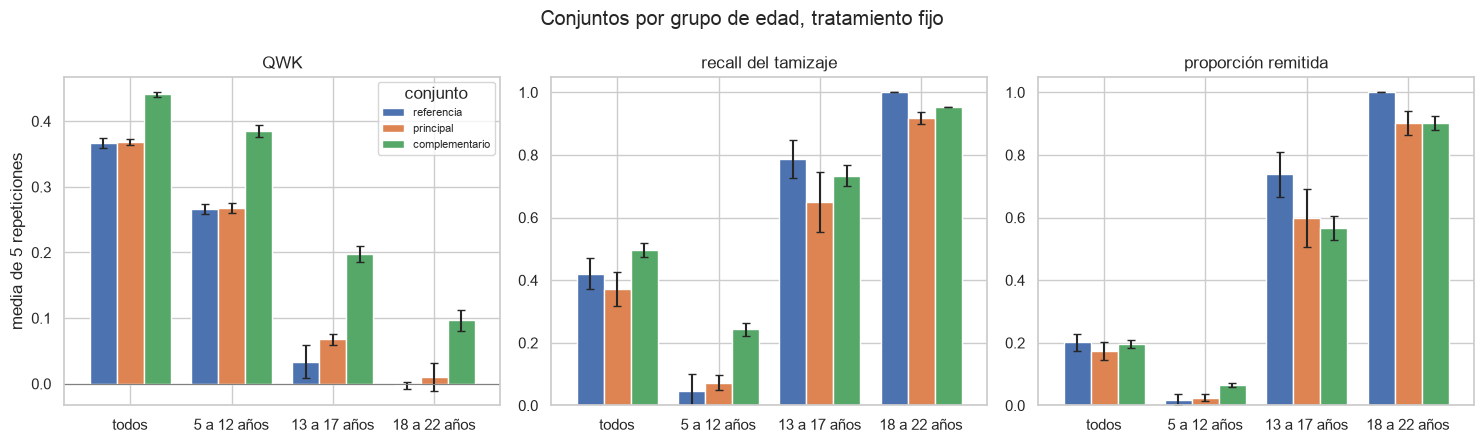

In [15]:
# QWK, recall del tamizaje y proporción remitida de los tres conjuntos en cada
# grupo de edad, con tratamiento fijo: media entre repeticiones y desviación como
# barra de error.
METRICAS_FIGURA_EDAD = {
    "qwk": "QWK",
    "screening_recall": "recall del tamizaje",
    "referred_share": "proporción remitida",
}
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))
for eje, (metrica, titulo) in zip(ejes, METRICAS_FIGURA_EDAD.items(), strict=True):
    agrupadas = {
        NOMBRES_CONJUNTOS[conjunto]: por_edad_repeticion[("fixed", conjunto)][
            metrica
        ].groupby(level="subgroup", sort=False)
        for conjunto in CONJUNTOS_EDAD
    }
    medias = pd.DataFrame({c: g.mean() for c, g in agrupadas.items()})
    desviaciones = pd.DataFrame({c: g.std() for c, g in agrupadas.items()})
    medias.rename(index={"all": "todos"}).plot.bar(
        yerr=desviaciones.rename(index={"all": "todos"}),
        ax=eje,
        capsize=3,
        rot=0,
        width=0.8,
        legend=False,
    )
    eje.axhline(0, color="gray", linewidth=0.8)
    if metrica != "qwk":
        eje.set_ylim(0, 1.05)
    eje.set_title(titulo)
    eje.set_xlabel("")
ejes[0].set_ylabel("media de 5 repeticiones")
ejes[0].legend(title="conjunto", fontsize=8)
fig.suptitle("Conjuntos por grupo de edad, tratamiento fijo")
fig.tight_layout()
save_figure(fig, "conjuntos_por_edad", FIGURAS)
plt.show()

### Conclusión

Las cifras siguientes son del análisis principal, con tratamiento fijo.

- **QWK dentro de cada grupo.** El complementario supera al principal y a la referencia en los tres grupos y en las cinco repeticiones:
  - *5 a 12 años.* El QWK sube de 0,268 con el principal a 0,385 con el complementario (diferencia 0,117). La referencia alcanza 0,266.
  - *13 a 17 años.* Sube de 0,068 a 0,197 (0,130); la referencia queda en 0,034.
  - *18 a 22 años.* Sube de 0,011 a 0,097 (0,086, con una desviación entre repeticiones de 0,027); la referencia está en cero.

  En cambio, el principal apenas se separa de la referencia en ningún grupo. Las variables físicas casi no distinguen a participantes de una misma edad; las complementarias sí.
- **Por qué la mejora es mayor dentro de los grupos.** Con todos los participantes, la diferencia es de 0,072; dentro de los grupos, de 0,086 a 0,130. El QWK global depende mucho de ordenar a los grupos de edad entre sí, algo que los tres conjuntos hacen por igual porque todos incluyen la edad. Por eso la diferencia global es menor que las diferencias dentro de cada grupo.
- **Tamizaje por grupo.**
  - *5 a 12 años.* El complementario remite al 6,5 % del grupo, frente al 2,5 % del principal. El recall del tamizaje sube de 0,073 a 0,244 y la subestimación baja de 0,938 a 0,774. Aun así, tres de cada cuatro niños con uso moderado o severo no se remiten.
  - *13 a 17 años.* El recall del tamizaje sube de 0,650 a 0,734 mientras la proporción remitida baja de 59,9 % a 56,7 %. El complementario remite a menos participantes y detecta a más. La referencia tiene un recall mayor (0,786), pero porque remite al 73,8 % del grupo.
  - *18 a 22 años.* Los dos conjuntos remiten a cerca del 90 % del grupo, así que el tamizaje casi no discrimina en este grupo. Con 84 participantes, sus cifras son poco precisas.
- **Sensibilidad.** Con el tratamiento elegido en cada partición, el patrón se repite: diferencias frente al principal de 0,116, 0,143 y 0,105, positivas en las cinco repeticiones de cada grupo.

La mejora de H4 no se debe a ordenar mejor los grupos de edad: las variables complementarias distinguen a participantes de una misma edad, algo que el conjunto principal casi no logra. La edad sigue marcando cuántos participantes se remiten: entre los 5 y los 12 años el modelo remite a muy pocos, y entre los 18 y los 22 a casi todos. Las tres configuraciones se comparan dentro de cada grupo en su propio punto de operación, sin igualar la proporción remitida.

## 7. Configuraciones de los experimentos iniciales

En la Entrega 2, H4 se probó con dos configuraciones fijas: regresión logística multinomial con imputación simple e indicadores, y gradient boosting con manejo nativo de los faltantes. Las dos usan la formulación multiclase, la ponderación de las clases y una búsqueda reducida de hiperparámetros (la fuerza de la regularización en la regresión logística; el número de iteraciones y de hojas en gradient boosting). Esta sección vuelve a evaluarlas con los conjuntos principal y complementario, con las mismas particiones, por dos razones:

- **Verificar la mejora reportada.** Las evaluaciones deben reproducir el QWK de cada conjunto, la diferencia de H4 y las métricas por nivel y de tamizaje que reportó la Entrega 2. Así, la mejora del complementario se confirma con cuatro configuraciones distintas: las dos iniciales y los dos análisis de la configuración seleccionada.
- **Comparar puntos de operación.** En la Entrega 2, las dos configuraciones trataban el nivel severo de forma opuesta. La regresión logística asignaba ese nivel a cientos de participantes y remitía a casi todos los severos. Gradient boosting casi no lo asignaba. Esa entrega no reportó la especificidad ni la proporción remitida. Aquí se calculan las métricas del escenario de tamizaje de las dos configuraciones y se comparan con las de la configuración seleccionada con tratamiento fijo.

La comparación es descriptiva y no incluye pruebas entre configuraciones. Las configuraciones iniciales no pasaron por la regla de selección, y cada una opera en su propio punto: una proporción remitida distinta implica otro balance entre recall y especificidad.

In [16]:
# Configuraciones de la Entrega 2 con los conjuntos principal y complementario,
# con las mismas particiones externas y en el caché de este notebook.
CONFIGURACIONES_ENTREGA_2 = {
    "logistic": ("regresión logística", make_logistic_search),
    "boosting": ("gradient boosting", make_boosting_search),
}
inicio = time.perf_counter()
iniciales = {}
for configuracion, (_, construir_modelo) in CONFIGURACIONES_ENTREGA_2.items():
    for conjunto in ("main", "complementary"):
        X_conjunto = analitico[conjuntos[conjunto]]
        modelo = construir_modelo(conjuntos[conjunto])
        inicio_evaluacion = time.perf_counter()
        iniciales[(configuracion, conjunto)] = run_nested_cv_cached(
            modelo,
            X_conjunto,
            y,
            particiones,
            name=f"initial__{configuracion}__multiclass__{conjunto}",
            cache_dir=CARPETA_CACHE,
            fields=evaluation_fields(
                modelo,
                X_conjunto,
                y,
                config={
                    "configuration": configuracion,
                    "formulation": "multiclass",
                    "feature_set": conjunto,
                },
                evaluation="initial_experiments",
                n_repeats=N_OUTER_REPEATS,
            ),
            n_jobs=N_PROCESOS,
            force=RECALCULAR,
        )
        conteo = iniciales[(configuracion, conjunto)].counts()
        print(
            f"{CONFIGURACIONES_ENTREGA_2[configuracion][0]}, "
            f"{NOMBRES_CONJUNTOS[conjunto]}: {conteo['loaded']} particiones "
            f"cargadas, {conteo['computed']} ajustadas, "
            f"{(time.perf_counter() - inicio_evaluacion) / 60:.1f} minutos"
        )
print(f"Minutos en esta ejecución: {(time.perf_counter() - inicio) / 60:.1f}")

# Todas las evaluaciones predicen a los mismos participantes en las mismas
# particiones.
for evaluacion in iniciales.values():
    assert len(evaluacion.folds) == len(particiones)
    assert np.array_equal(
        evaluacion.predictions["y_true"].to_numpy(),
        y[evaluacion.predictions["position"].to_numpy()],
    )

regresión logística, principal: 25 particiones cargadas, 0 ajustadas, 0.0 minutos
regresión logística, complementario: 25 particiones cargadas, 0 ajustadas, 0.0 minutos
gradient boosting, principal: 25 particiones cargadas, 0 ajustadas, 0.0 minutos
gradient boosting, complementario: 25 particiones cargadas, 0 ajustadas, 0.0 minutos
Minutos en esta ejecución: 0.0


In [17]:
# Cifras de la Entrega 2 que las evaluaciones deben reproducir: QWK medio
# (Tabla 15), diferencia media de H4 (Tabla 16) y métricas por nivel y de
# tamizaje (Tabla 17), todas redondeadas a tres decimales.
QWK_ENTREGA_2 = {
    ("logistic", "main"): 0.308,
    ("logistic", "complementary"): 0.384,
    ("boosting", "main"): 0.315,
    ("boosting", "complementary"): 0.393,
}
DIFERENCIA_H4_ENTREGA_2 = {"logistic": 0.076, "boosting": 0.078}
TABLA_17_ENTREGA_2 = {
    ("logistic", "main"): {
        "recall moderado": 0.329,
        "recall severo": 0.594,
        "subestimación moderado o severo": 0.427,
        "recall del tamizaje": 0.600,
        "proporción de severos remitidos": 0.918,
        "asignados a severo": 370,
    },
    ("logistic", "complementary"): {
        "recall moderado": 0.380,
        "recall severo": 0.571,
        "subestimación moderado o severo": 0.421,
        "recall del tamizaje": 0.608,
        "proporción de severos remitidos": 0.924,
        "asignados a severo": 254,
    },
    ("boosting", "main"): {
        "recall moderado": 0.353,
        "recall severo": 0.153,
        "subestimación moderado o severo": 0.608,
        "recall del tamizaje": 0.433,
        "proporción de severos remitidos": 0.653,
        "asignados a severo": 88,
    },
    ("boosting", "complementary"): {
        "recall moderado": 0.386,
        "recall severo": 0.171,
        "subestimación moderado o severo": 0.574,
        "recall del tamizaje": 0.471,
        "proporción de severos remitidos": 0.718,
        "asignados a severo": 65,
    },
}
TOLERANCIA_REDONDEO = 0.0005 + 1e-9


def asignados_a_severo(predicciones: pd.DataFrame) -> float:
    """Participantes a los que se asigna el nivel severo, en promedio por repetición."""
    return float(
        (predicciones["y_pred"] == SEVERE_LEVEL)
        .groupby(predicciones["repeat"])
        .sum()
        .mean()
    )


filas = {}
for (configuracion, conjunto), evaluacion in iniciales.items():
    calculadas = {
        "QWK medio": evaluacion.folds["qwk"].mean(),
        **{
            metrica: TASAS_POR_PARTICIPANTE[metrica](evaluacion.predictions).mean()
            for metrica in TABLA_17_ENTREGA_2[(configuracion, conjunto)]
            if metrica != "asignados a severo"
        },
        "asignados a severo": asignados_a_severo(evaluacion.predictions),
    }
    reportadas = {
        "QWK medio": QWK_ENTREGA_2[(configuracion, conjunto)],
        **TABLA_17_ENTREGA_2[(configuracion, conjunto)],
    }
    for metrica, valor in calculadas.items():
        tolerancia = 0.5 if metrica == "asignados a severo" else TOLERANCIA_REDONDEO
        assert abs(valor - reportadas[metrica]) <= tolerancia, (
            configuracion,
            conjunto,
            metrica,
            valor,
        )
        filas[
            (
                CONFIGURACIONES_ENTREGA_2[configuracion][0],
                NOMBRES_CONJUNTOS[conjunto],
                metrica,
            )
        ] = {"calculada": valor, "Entrega 2": reportadas[metrica]}

# Diferencia de H4 con cada configuración inicial, partición por partición.
for configuracion, (nombre, _) in CONFIGURACIONES_ENTREGA_2.items():
    diferencias = paired_differences(
        iniciales[(configuracion, "complementary")].folds,
        iniciales[(configuracion, "main")].folds,
    )
    diferencia = diferencias["difference"].mean()
    assert (
        abs(diferencia - DIFERENCIA_H4_ENTREGA_2[configuracion]) <= TOLERANCIA_REDONDEO
    )
    filas[(nombre, "complementario − principal", "diferencia media de QWK")] = {
        "calculada": diferencia,
        "Entrega 2": DIFERENCIA_H4_ENTREGA_2[configuracion],
    }
    filas[(nombre, "complementario − principal", "particiones con mejora")] = {
        "calculada": int((diferencias["difference"] > 0).sum()),
        "Entrega 2": len(particiones),
    }
verificacion_entrega_2 = pd.DataFrame.from_dict(filas, orient="index").rename_axis(
    ["configuración", "conjunto", "métrica"]
)
verificacion_entrega_2.round(3)

calculada  \
configuración       conjunto                   métrica                                      
regresión logística principal                  QWK medio                            0.308   
                                               recall moderado                      0.329   
                                               recall severo                        0.594   
                                               subestimación moderado o severo      0.427   
                                               recall del tamizaje                  0.600   
                                               proporción de severos remitidos      0.918   
                                               asignados a severo                 369.800   
                    complementario             QWK medio                            0.384   
                                               recall moderado                      0.380   
                                               recall severo                        0.571   
                                               subestimación moderado o severo      0.421   
                                               recall del tamizaje                  0.608   
                                               proporción de severos remitidos      0.924   
                                               asignados a severo                 254.000   
gradient boosting   principal                  QWK medio                            0.315   
                                               recall moderado                      0.353   
                                               recall severo                        0.153   
                                               subestimación moderado o severo      0.608   
                                               recall del tamizaje                  0.433   
                                               proporción de severos remitidos      0.653   
                                               asignados a severo                  88.000   
                    complementario             QWK medio                            0.393   
                                               recall moderado                      0.386   
                                               recall severo                        0.171   
                                               subestimación moderado o severo      0.574   
                                               recall del tamizaje                  0.471   
                                               proporción de severos remitidos      0.718   
                                               asignados a severo                  64.800   
regresión logística complementario − principal diferencia media de QWK              0.076   
                                               particiones con mejora              25.000   
gradient boosting   complementario − principal diferencia media de QWK              0.078   
                                               particiones con mejora              25.000   

                                                                                Entrega 2  
configuración       conjunto                   métrica                                     
regresión logística principal                  QWK medio                            0.308  
                                               recall moderado                      0.329  
                                               recall severo                        0.594  
                                               subestimación moderado o severo      0.427  
                                               recall del tamizaje                  0.600  
                                               proporción de severos remitidos      0.918  
                                               asignados a severo                 370.000  
                    complementario             QWK medio                            0.384

In [18]:
# Puntos de operación de las configuraciones iniciales y de la configuración
# seleccionada (tratamiento fijo), con los dos conjuntos: media entre
# repeticiones de cada métrica.
METRICAS_OPERACION = [
    "recall moderado",
    "recall severo",
    "subestimación moderado o severo",
    "recall del tamizaje",
    "especificidad del tamizaje",
    "proporción remitida",
    "proporción de severos remitidos",
]
evaluaciones_operacion = {
    (nombre, conjunto): iniciales[(configuracion, conjunto)]
    for configuracion, (nombre, _) in CONFIGURACIONES_ENTREGA_2.items()
    for conjunto in ("main", "complementary")
} | {
    ("seleccionada (tratamiento fijo)", conjunto): resultados[(conjunto, "fixed")]
    for conjunto in ("main", "complementary")
}
filas = {}
for (nombre, conjunto), evaluacion in evaluaciones_operacion.items():
    tamizaje = screening_by_repeat(evaluacion.predictions).mean()
    # Las tasas por participante reproducen las métricas del tamizaje por
    # repetición.
    assert np.isclose(
        TASAS_POR_PARTICIPANTE["especificidad del tamizaje"](
            evaluacion.predictions
        ).mean(),
        tamizaje["specificity"],
    )
    filas[(nombre, NOMBRES_CONJUNTOS[conjunto])] = {
        "QWK": evaluacion.folds["qwk"].mean(),
        **{
            metrica: TASAS_POR_PARTICIPANTE[metrica](evaluacion.predictions).mean()
            for metrica in METRICAS_OPERACION
        },
        "valor predictivo positivo": tamizaje["ppv"],
        "asignados a severo": asignados_a_severo(evaluacion.predictions),
    }
puntos_operacion = pd.DataFrame.from_dict(filas, orient="index").rename_axis(
    ["configuración", "conjunto"]
)
puntos_operacion.round(3)

QWK  recall moderado  \
configuración                   conjunto                                 
regresión logística             principal       0.308            0.329   
                                complementario  0.384            0.380   
gradient boosting               principal       0.315            0.353   
                                complementario  0.393            0.386   
seleccionada (tratamiento fijo) principal       0.369            0.341   
                                complementario  0.441            0.441   

                                                recall severo  \
configuración                   conjunto                        
regresión logística             principal               0.594   
                                complementario          0.571   
gradient boosting               principal               0.153   
                                complementario          0.171   
seleccionada (tratamiento fijo) principal               0.000   
                                complementario          0.118   

                                                subestimación moderado o severo  \
configuración                   conjunto                                          
regresión logística             principal                                 0.427   
                                complementario                            0.421   
gradient boosting               principal                                 0.608   
                                complementario                            0.574   
seleccionada (tratamiento fijo) principal                                 0.687   
                                complementario                            0.564   

                                                recall del tamizaje  \
configuración                   conjunto                              
regresión logística             principal                     0.600   
                                complementario                0.608   
gradient boosting               principal                     0.433   
                                complementario                0.471   
seleccionada (tratamiento fijo) principal                     0.371   
                                complementario                0.497   

                                                especificidad del tamizaje  \
configuración                   conjunto                                     
regresión logística             principal                            0.721   
                                complementario                       0.767   
gradient boosting               principal                            0.787   
                                complementario                       0.819   
seleccionada (tratamiento fijo) principal                            0.861   
                                complementario                       0.856   

                                                proporción remitida  \
configuración                   conjunto                              
regresión logística             principal                     0.327   
                                complementario                0.289   
gradient boosting               principal                     0.247   
                                complementario                0.225   
seleccionada (tratamiento fijo) principal                     0.174   
                                complementario                0.198   

                                                proporción de severos remitidos  \
configuración                   conjunto                                          
regresión logística             principal                                 0.918   
                                complementario                            0.924   
gradient boosting               principal                                 0.653   
                                complementario                            0.718   
selecciona

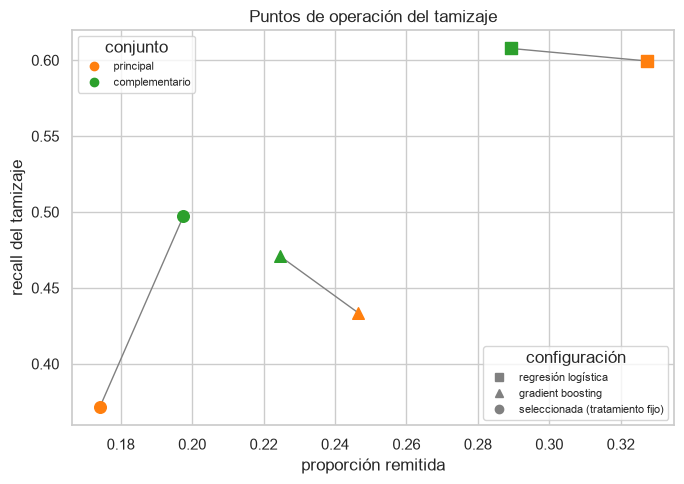

In [19]:
# Recall del tamizaje frente a la proporción remitida de cada configuración y
# conjunto. Las líneas unen el principal con el complementario de una misma
# configuración.
MARCADORES = {
    "regresión logística": "s",
    "gradient boosting": "^",
    "seleccionada (tratamiento fijo)": "o",
}
COLORES_CONJUNTO = {"principal": "tab:orange", "complementario": "tab:green"}
fig, eje = plt.subplots(figsize=(7, 5))
for nombre, marcador in MARCADORES.items():
    puntos = puntos_operacion.loc[nombre]
    eje.plot(
        puntos["proporción remitida"],
        puntos["recall del tamizaje"],
        color="gray",
        linewidth=1,
        zorder=1,
    )
    for conjunto, fila in puntos.iterrows():
        eje.scatter(
            fila["proporción remitida"],
            fila["recall del tamizaje"],
            marker=marcador,
            s=70,
            color=COLORES_CONJUNTO[conjunto],
            zorder=2,
        )
# Leyendas separadas para la configuración (forma) y el conjunto (color).
leyenda_configuracion = eje.legend(
    handles=[
        plt.Line2D([], [], marker=m, linestyle="", color="gray", label=n)
        for n, m in MARCADORES.items()
    ],
    title="configuración",
    fontsize=8,
    loc="lower right",
)
eje.add_artist(leyenda_configuracion)
eje.legend(
    handles=[
        plt.Line2D([], [], marker="o", linestyle="", color=c, label=n)
        for n, c in COLORES_CONJUNTO.items()
    ],
    title="conjunto",
    fontsize=8,
    loc="upper left",
)
eje.set_xlabel("proporción remitida")
eje.set_ylabel("recall del tamizaje")
eje.set_title("Puntos de operación del tamizaje")
fig.tight_layout()
save_figure(fig, "puntos_operacion", FIGURAS)
plt.show()

### Conclusión

- **Reproducción.** Las dos configuraciones de la Entrega 2 reproducen a tres decimales lo reportado en esa entrega:
  - el QWK de cada conjunto;
  - la diferencia de H4: 0,076 con la regresión logística y 0,078 con gradient boosting, positiva en las 25 particiones;
  - el recall por nivel, la subestimación, el recall del tamizaje y la proporción de severos remitidos.
- **H4 con cuatro configuraciones.** La mejora del complementario es de 0,076 y 0,078 con las configuraciones iniciales, y de 0,073 y 0,076 con los dos análisis de la configuración seleccionada. En los cuatro casos es positiva en las 25 particiones. Su tamaño casi no depende del algoritmo, de la formulación ni del tratamiento de los faltantes.
- **Puntos de operación con el conjunto complementario.** Las tres configuraciones remiten a proporciones muy distintas de participantes:
  - *Regresión logística.* Remite al 28,9 %, con un recall del tamizaje de 0,608, una especificidad de 0,767 y un valor predictivo positivo de 0,316. Remite al 92,4 % de los severos. Su recall severo de 0,571 se logra asignando el nivel severo a 254 participantes por repetición, cuando solo hay 34 severos, así que ese nivel no informa la severidad.
  - *Gradient boosting.* Remite al 22,5 %, con un recall de 0,471, una especificidad de 0,819 y un valor predictivo positivo de 0,315. Remite al 71,8 % de los severos.
  - *Configuración seleccionada.* Remite al 19,8 %, con un recall de 0,497, una especificidad de 0,856 y el mayor valor predictivo positivo de las tres, 0,379. Remite al 85,3 % de los severos y asigna el nivel severo a 26 participantes por repetición.
- **Comparación entre configuraciones.** Con el complementario, la configuración seleccionada supera a gradient boosting en las cuatro métricas del tamizaje: detecta más, remite a menos, y tiene mayor especificidad y valor predictivo positivo. Frente a la regresión logística no hay una mejor en todo. La logística detecta más moderados o severos (0,608 frente a 0,497) y más severos, pero remite a 9 puntos porcentuales más de participantes, con una especificidad de 0,767 frente a 0,856.
- **Efecto del complementario en el punto de operación.**
  - En la regresión logística y en gradient boosting, el complementario reduce la proporción remitida (de 32,7 % a 28,9 % y de 24,7 % a 22,5 %) sin perder recall.
  - En la configuración seleccionada, la proporción remitida sube de 17,4 % a 19,8 % y el recall, de 0,371 a 0,497.
  - En las tres, el valor predictivo positivo aumenta en unos 4 a 6 puntos.

Las configuraciones con un QWK parecido difieren sobre todo en cuántos participantes remiten. El QWK no resume esa diferencia: un tamizaje con más remisiones detecta más casos a cambio de más falsos positivos. La comparación es descriptiva:

- Las configuraciones iniciales no pasaron por la regla de selección.
- La configuración seleccionada se eligió con la tasa de subestimación como desempate, sobre las mismas particiones, así que sus métricas de los niveles altos pueden tener un sesgo optimista de magnitud desconocida.

## 8. Tablas exportadas y conclusiones

Esta sección deja los resultados del notebook listos para el informe:

- **Resumen del objetivo 4.** Una tabla reúne las diferencias entre el complementario y el principal que sustentan las recomendaciones:
  - la diferencia de QWK de H4 en los dos análisis;
  - las diferencias por nivel y en el tamizaje de la sección 5;
  - las diferencias de QWK dentro de cada grupo de edad de la sección 6.

  Cada diferencia va con el valor de cada conjunto, su variabilidad, su intervalo cuando existe y el número de participantes sobre el que se calcula. La variabilidad de las diferencias por nivel es su desviación entre repeticiones, que se calcula aquí.
- **Insumos del objetivo 5.** El objetivo 5 pide al menos una recomendación por cada uno de los objetivos 2, 3 y 4, cada una vinculada con su métrica, su valor, su variabilidad y su limitación. Por eso una segunda tabla reúne las métricas centrales de los tres objetivos, con el notebook del que proviene cada una:
  - H2 y H3, de la búsqueda de modelos;
  - el desempeño por nivel y el escenario de tamizaje, del análisis de errores;
  - el resumen de este notebook.

  Antes de unirlas se verifica que las tablas leídas coincidan con el registro de la búsqueda y con las evaluaciones recalculadas aquí.
- **Tablas y figuras.** Las tablas se guardan en CSV, con las mismas etiquetas que se muestran. Antes se verifica que ninguna tenga columnas de identificación o de posición de participantes y que todas sean pequeñas, como corresponde a resúmenes. También se verifica que las figuras del notebook estén en su carpeta.

Al final se libera el caché del preprocesamiento de este notebook, que solo se usaría para volver a ajustar alguna partición.

In [ ]:
# Métricas de todos los participantes en cada repetición, para la desviación
# entre repeticiones de las diferencias por nivel y de tamizaje.
def metricas_por_repeticion(predicciones: pd.DataFrame) -> pd.DataFrame:
    """Recall por nivel, subestimación y métricas del tamizaje en cada repetición."""
    todos = subgroup_metrics_by_repeat(predicciones, grupo_edad).xs(
        "all", level="subgroup"
    )
    return pd.DataFrame(
        {
            "recall ninguno": todos["recall_0"],
            "recall leve": todos["recall_1"],
            "recall moderado": todos["recall_2"],
            "recall severo": todos["recall_3"],
            "subestimación moderado o severo": todos["underestimation"],
            "recall del tamizaje": todos["screening_recall"],
            "especificidad del tamizaje": screening_by_repeat(predicciones)[
                "specificity"
            ],
            "proporción remitida": todos["referred_share"],
            "proporción de severos remitidos": level_referral_by_repeat(
                predicciones, SEVERE_LEVEL
            )["share"],
        }
    )


filas = {}
# Diferencia de QWK de H4 en los dos análisis (sección 4).
for analisis, nombre_analisis in NOMBRES_ANALISIS.items():
    prueba = pruebas_h4.loc[analisis]
    filas[f"QWK (H4), {nombre_analisis}"] = {
        "sección": "4",
        "principal": prueba["QWK principal"],
        "complementario": prueba["QWK complementario"],
        "diferencia": prueba["diferencia media de QWK"],
        "desviación de la diferencia": prueba["desviación de la diferencia"],
        "desviación entre": "particiones",
        "intervalo 95 % inferior": prueba[
            f"cota inferior unilateral del {SUPERIORITY_CONFIDENCE:.0%}"
        ],
        "intervalo 95 % superior": np.nan,
        "participantes": len(y),
        "intervalo": "cota inferior unilateral",
    }

# Diferencias por nivel y de tamizaje, con tratamiento fijo (sección 5).
por_repeticion_conjunto = {
    conjunto: metricas_por_repeticion(resultados[(conjunto, "fixed")].predictions)
    for conjunto in ("main", "complementary")
}
diferencias_repeticion = (
    por_repeticion_conjunto["complementary"] - por_repeticion_conjunto["main"]
)
pareada_fija = comparacion_pareada.loc[NOMBRES_ANALISIS["fixed"]]
for metrica in pareada_fija.index:
    fila = pareada_fija.loc[metrica]
    # La media de las diferencias por repetición es la diferencia pareada.
    assert np.isclose(diferencias_repeticion[metrica].mean(), fila["diferencia"])
    filas[metrica] = {
        "sección": "5",
        "principal": fila["principal"],
        "complementario": fila["complementario"],
        "diferencia": fila["diferencia"],
        "desviación de la diferencia": diferencias_repeticion[metrica].std(),
        "desviación entre": "repeticiones",
        "intervalo 95 % inferior": fila["intervalo 95 % inferior"],
        "intervalo 95 % superior": fila["intervalo 95 % superior"],
        "participantes": fila["participantes"],
        "intervalo": "remuestreo de participantes",
    }

# Diferencias de QWK dentro de cada grupo de edad, con tratamiento fijo (sección
# 6). Los índices se ordenan para seleccionar por niveles sin recorrerlos enteros.
diferencias_edad_fija = diferencias_edad.sort_index().loc[
    (NOMBRES_ANALISIS["fixed"], "complementario − principal")
]
qwk_edad_fija = edad_conjuntos.sort_index().loc[NOMBRES_ANALISIS["fixed"], "QWK"]
for subgrupo in grupo_edad.cat.categories:
    filas[f"QWK dentro del grupo de {subgrupo}"] = {
        "sección": "6",
        "principal": qwk_edad_fija.loc[(subgrupo, "principal")],
        "complementario": qwk_edad_fija.loc[(subgrupo, "complementario")],
        "diferencia": diferencias_edad_fija.loc[subgrupo, "diferencia media de QWK"],
        "desviación de la diferencia": diferencias_edad_fija.loc[
            subgrupo, "desviación entre repeticiones"
        ],
        "desviación entre": "repeticiones",
        "intervalo 95 % inferior": np.nan,
        "intervalo 95 % superior": np.nan,
        "participantes": tamanos_edad.loc[subgrupo, "participantes"],
        "intervalo": "sin intervalo",
    }
resumen_objetivo_4 = pd.DataFrame.from_dict(filas, orient="index").rename_axis(
    "métrica"
)
resumen_objetivo_4["participantes"] = resumen_objetivo_4["participantes"].astype(
    "Int64"
)
resumen_objetivo_4.round(3)

/var/folders/p4/gx9vbn9x3r155vcdnyljf8_m0000gn/T/ipykernel_55624/2214085673.py:73: PerformanceWarning: indexing past lexsort depth may impact performance.
  diferencias_edad_fija = diferencias_edad.loc[
/var/folders/p4/gx9vbn9x3r155vcdnyljf8_m0000gn/T/ipykernel_55624/2214085673.py:77: PerformanceWarning: indexing past lexsort depth may impact performance.
  medias_grupo = edad_conjuntos.loc[(NOMBRES_ANALISIS["fixed"], subgrupo), "QWK"]
/var/folders/p4/gx9vbn9x3r155vcdnyljf8_m0000gn/T/ipykernel_55624/2214085673.py:77: PerformanceWarning: indexing past lexsort depth may impact performance.
  medias_grupo = edad_conjuntos.loc[(NOMBRES_ANALISIS["fixed"], subgrupo), "QWK"]
/var/folders/p4/gx9vbn9x3r155vcdnyljf8_m0000gn/T/ipykernel_55624/2214085673.py:77: PerformanceWarning: indexing past lexsort depth may impact performance.
  medias_grupo = edad_conjuntos.loc[(NOMBRES_ANALISIS["fixed"], subgrupo), "QWK"]


,sección,principal,complementario,diferencia,desviación de la diferencia,desviación entre,intervalo 95 % inferior,intervalo 95 % superior,participantes,intervalo
métrica,,,,,,,,,,
"QWK (H4), tratamiento fijo",4,0.369,0.441,0.073,0.035,particiones,0.040,NaN,2736,cota inferior unilateral
"QWK (H4), tratamiento elegido en cada partición",4,0.365,0.441,0.075,0.037,particiones,0.041,NaN,2736,cota inferior unilateral
recall ninguno,5,0.654,0.681,0.028,0.028,repeticiones,0.010,0.045,1594,remuestreo de participantes
recall leve,5,0.390,0.378,-0.012,0.071,repeticiones,-0.046,0.022,730,remuestreo de participantes
recall moderado,5,0.341,0.441,0.099,0.073,repeticiones,0.058,0.142,378,remuestreo de participantes
recall severo,5,0.000,0.118,0.118,0.055,repeticiones,0.041,0.212,34,remuestreo de participantes
subestimación moderado o severo,5,0.687,0.564,-0.123,0.060,repeticiones,-0.160,-0.087,412,remuestreo de participantes
recall del tamizaje,5,0.371,0.497,0.126,0.067,repeticiones,0.088,0.164,412,remuestreo de participantes
especificidad del tamizaje,5,0.861,0.856,-0.005,0.035,repeticiones,-0.015,0.005,2324,remuestreo de participantes


In [21]:
# Insumos de las recomendaciones del objetivo 5: métricas centrales de los
# objetivos 2 a 4, leídas de las tablas exportadas por cada notebook.
NOTEBOOK_03 = "03_busqueda_modelos"
NOTEBOOK_04 = "04_interpretabilidad_errores"
NOTEBOOK_05 = "05_comparacion_complementario"
pruebas_h2_h3 = pd.read_csv(
    TABLES_DIR / NOTEBOOK_03 / "pruebas_h2_h3.csv", index_col="hipótesis"
)
resumen_04 = pd.read_csv(
    TABLES_DIR / NOTEBOOK_04 / "resumen_objetivo_5.csv", index_col="métrica"
)

# Las tablas leídas coinciden con el registro de la búsqueda y con las
# evaluaciones de este notebook.
for hipotesis, conclusion in registro["hypotheses"]["fixed_treatment"].items():
    fila_hipotesis = pruebas_h2_h3[pruebas_h2_h3.index.str.startswith(f"{hipotesis}:")]
    assert len(fila_hipotesis) == 1
    assert fila_hipotesis["conclusión"].iloc[0] == conclusion
diferencia_h2 = paired_differences(
    resultados[("main", "fixed")].folds, referencias["fixed"].folds
)["difference"].mean()
assert np.isclose(
    pruebas_h2_h3.filter(like="H2:", axis="index")["diferencia media de QWK"].iloc[0],
    diferencia_h2,
)
seleccionada = resultados[("main", "chosen")].predictions
assert np.isclose(resumen_04.loc["QWK", "media"], registro["selected"]["mean_qwk"])
assert np.isclose(
    resumen_04.loc["recall del tamizaje", "media"],
    screening_by_repeat(seleccionada)["recall"].mean(),
)

filas = []
# Objetivo 2: H2 y H3 con tratamiento fijo, con el límite superior del análisis
# de aporte despreciable.
for hipotesis, fila in pruebas_h2_h3.iterrows():
    filas.append(
        {
            "objetivo": 2,
            "notebook": NOTEBOOK_03,
            "métrica": f"{hipotesis}: diferencia media de QWK",
            "valor": fila["diferencia media de QWK"],
            "desviación": fila["desviación de la diferencia"],
            "desviación entre": "particiones",
            "intervalo 95 % inferior": np.nan,
            "intervalo 95 % superior": fila["límite superior unilateral del 95 %"],
            "intervalo": "límite superior unilateral",
            "participantes": len(y),
        }
    )
# Objetivo 3: desempeño por nivel y escenario de tamizaje del modelo seleccionado.
for metrica, fila in resumen_04.iterrows():
    filas.append(
        {
            "objetivo": 3,
            "notebook": NOTEBOOK_04,
            "métrica": metrica,
            "valor": fila["media"],
            "desviación": fila["desviación entre repeticiones"],
            "desviación entre": "repeticiones",
            "intervalo 95 % inferior": fila["intervalo 95 % inferior"],
            "intervalo 95 % superior": fila["intervalo 95 % superior"],
            "intervalo": fila["intervalo"],
            "participantes": fila["participantes"],
        }
    )
# Objetivo 4: diferencias complementario − principal de este notebook.
for metrica, fila in resumen_objetivo_4.iterrows():
    filas.append(
        {
            "objetivo": 4,
            "notebook": NOTEBOOK_05,
            "métrica": f"{metrica}: complementario − principal",
            "valor": fila["diferencia"],
            "desviación": fila["desviación de la diferencia"],
            "desviación entre": fila["desviación entre"],
            "intervalo 95 % inferior": fila["intervalo 95 % inferior"],
            "intervalo 95 % superior": fila["intervalo 95 % superior"],
            "intervalo": fila["intervalo"],
            "participantes": fila["participantes"],
        }
    )
insumos_objetivo_5 = pd.DataFrame(filas).set_index(["objetivo", "métrica"])
insumos_objetivo_5["participantes"] = insumos_objetivo_5["participantes"].astype(
    "Int64"
)
insumos_objetivo_5.round(3)

notebook  \
objetivo métrica                                                                                                      
2        H2: principal frente a referencia: diferencia media de QWK                             03_busqueda_modelos   
         H3: principal frente a principal sin actigrafía: diferencia media de QWK               03_busqueda_modelos   
3        QWK                                                                           04_interpretabilidad_errores   
         recall moderado                                                               04_interpretabilidad_errores   
         recall severo                                                                 04_interpretabilidad_errores   
         subestimación moderado o severo                                               04_interpretabilidad_errores   
         recall del tamizaje                                                           04_interpretabilidad_errores   
         especificidad del tamizaje                                                    04_interpretabilidad_errores   
         valor predictivo positivo del tamizaje                                        04_interpretabilidad_errores   
         proporción remitida                                                           04_interpretabilidad_errores   
         proporción de severos remitidos                                               04_interpretabilidad_errores   
4        QWK (H4), tratamiento fijo: complementario − principal                       05_comparacion_complementario   
         QWK (H4), tratamiento elegido en cada partición: complementario − principal  05_comparacion_complementario   
         recall ninguno: complementario − principal                                   05_comparacion_complementario   
         recall leve: complementario − principal                                      05_comparacion_complementario   
         recall moderado: complementario − principal                                  05_comparacion_complementario   
         recall severo: complementario − principal                                    05_comparacion_complementario   
         subestimación moderado o severo: complementario − principal                  05_comparacion_complementario   
         recall del tamizaje: complementario − principal                              05_comparacion_complementario   
         especificidad del tamizaje: complementario − principal                       05_comparacion_complementario   
         proporción remitida: complementario − principal                              05_comparacion_complementario   
         proporción de severos remitidos: complementario − principal                  05_comparacion_complementario   
         QWK dentro del grupo de 5 a 12 años: complementario − principal              05_comparacion_complementario   
         QWK dentro del grupo de 13 a 17 años: complementario − principal             05_comparacion_complementario   
         QWK dentro del grupo de 18 a 22 años: complementario − principal             05_comparacion_complementario   

                                                                                      valor  \
objetivo métrica                                                                              
2        H2: principal frente a referencia: diferencia media de QWK                   0.002   
         H3: principal frente a principal sin actigrafía: diferencia media de QWK    -0.003   
3        QWK                                                                          0.365   
         recall moderado                                                              0.346   
         recall severo                                                                0.000   
         subestimación moderado o severo                                              0.683   
         recall del tamizaje                                                          0.375   
         especificidad del tamizaje   

In [22]:
# Tablas agregadas del notebook, para el informe, con las mismas etiquetas que se
# muestran: ninguna contiene filas por participante.
TABLAS_EXPORTADAS = {
    "resumen_objetivo_4": resumen_objetivo_4,
    "insumos_objetivo_5": insumos_objetivo_5,
    "cobertura_complementarias": cobertura,
    "evaluaciones": evaluaciones,
    "tratamiento_elegido": tratamiento_elegido,
    "pruebas_h4": pruebas_h4.rename(index=NOMBRES_ANALISIS).rename_axis("análisis"),
    "diferencias_h4_por_particion": pd.concat(
        {
            NOMBRES_ANALISIS[analisis]: diferencias.set_index(["repeat", "fold"])
            for analisis, diferencias in diferencias_h4.items()
        },
        names=["análisis", "repetición", "partición"],
    ).rename(
        columns={
            "n_train": "participantes de entrenamiento",
            "n_test": "participantes de evaluación",
            "qwk_a": "QWK complementario",
            "qwk_b": "QWK principal",
            "difference": "diferencia",
        }
    ),
    "comparacion_pareada": comparacion_pareada,
    "tamizaje_conjuntos": tamizaje_conjuntos,
    "edad_tamanos": tamanos_edad,
    "edad_conjuntos": edad_conjuntos,
    "edad_diferencias": diferencias_edad,
    "entrega_2_verificacion": verificacion_entrega_2,
    "puntos_operacion": puntos_operacion,
}
# Control de privacidad: ninguna tabla tiene columnas de identificación o de
# posición de participantes, y todas son pequeñas, como corresponde a resúmenes.
for nombre, tabla in TABLAS_EXPORTADAS.items():
    columnas = {str(c).lower() for c in [*tabla.columns, *tabla.index.names]}
    assert not columnas & {"id", "position", "posición"}, nombre
    assert len(tabla) < 100, nombre

TABLAS.mkdir(parents=True, exist_ok=True)
for nombre, tabla in TABLAS_EXPORTADAS.items():
    tabla.to_csv(TABLAS / f"{nombre}.csv")
RAIZ = TABLES_DIR.parents[1]
print(f"{len(TABLAS_EXPORTADAS)} tablas guardadas en {TABLAS.relative_to(RAIZ)}")

# Las figuras del notebook quedan en su carpeta de reports/figures.
FIGURAS_NOTEBOOK = (
    "diferencias_h4",
    "diferencias_por_nivel",
    "conjuntos_por_edad",
    "puntos_operacion",
)
assert all((FIGURAS / f"{nombre}.png").exists() for nombre in FIGURAS_NOTEBOOK)
print(
    f"{len(FIGURAS_NOTEBOOK)} figuras en {FIGURAS.relative_to(RAIZ)}: "
    + ", ".join(FIGURAS_NOTEBOOK)
)

# El caché de Pipeline(memory=...) solo se usaría para reajustar particiones.
clear_pipeline_memory(CARPETA_MEMORIA)

14 tablas guardadas en reports/tables/05_comparacion_complementario
4 figuras en reports/figures/05_comparacion_complementario: diferencias_h4, diferencias_por_nivel, conjuntos_por_edad, puntos_operacion


### Verificación del criterio de cumplimiento

La Tabla 2 de la formulación define el criterio de cumplimiento del objetivo 4: la diferencia de desempeño entre los dos conjuntos de variables, evaluada sobre los mismos participantes y con el mismo procedimiento de validación. Cada elemento se cumple en este notebook así:

| Elemento del criterio | Sección | Figuras | Tablas exportadas |
|---|---|---|---|
| Mismos participantes, mismas particiones y misma configuración en los dos conjuntos | 1 a 3 | — | `cobertura_complementarias`, `evaluaciones`, `tratamiento_elegido` |
| Diferencia pareada de QWK y prueba de H4, con su sensibilidad y su cota inferior | 4 | `diferencias_h4` | `pruebas_h4`, `diferencias_h4_por_particion` |
| Diferencia por nivel de severidad y en el escenario de tamizaje | 5 | `diferencias_por_nivel` | `comparacion_pareada`, `tamizaje_conjuntos` |
| Diferencia dentro de cada grupo de edad, con la referencia demográfica | 6 | `conjuntos_por_edad` | tablas con prefijo `edad_` |
| Verificación con las configuraciones de la Entrega 2 y sus puntos de operación | 7 | `puntos_operacion` | `entrega_2_verificacion`, `puntos_operacion` |
| Diferencias con su variabilidad, e insumos de los objetivos 2 a 4 para el objetivo 5 | 8 | — | `resumen_objetivo_4`, `insumos_objetivo_5` |

### Conclusión

Este notebook desarrolló el objetivo específico 4: cuantificó el cambio en el desempeño al agregar al conjunto principal tres variables de sueño, funcionamiento global y uso de internet, con los mismos participantes, las mismas particiones y la misma configuración.

- **H4 se sostiene.** Con el tratamiento fijo de los faltantes, el QWK medio sube de 0,369 a 0,441. La diferencia es de 0,073 y es positiva en las 25 particiones externas, con un valor p de 0,0004. Con el tratamiento elegido en cada partición, la conclusión se confirma (diferencia de 0,075). La cota inferior unilateral del 95 % es 0,040 en los dos análisis. Las dos configuraciones de la Entrega 2 reproducen una mejora del mismo tamaño (0,076 y 0,078), así que el resultado no depende del modelo.
- **Por nivel y en el tamizaje.** La mejora se concentra en los niveles altos:
  - el recall moderado sube 0,099;
  - la subestimación de los moderados o severos baja de 0,687 a 0,564;
  - el recall del tamizaje sube de 0,371 a 0,497, mientras la proporción remitida pasa de 17,4 % a 19,8 % y la especificidad se mantiene en 0,86.

  El nivel leve no mejora. El severo casi nunca se reconoce como tal (recall de 0,118), y la mejora en la proporción de severos remitidos (de 0,706 a 0,853) no queda establecida con 34 casos.
- **Dentro de cada grupo de edad.** El complementario mejora el QWK entre 0,086 y 0,130 en los tres grupos y en todas las repeticiones, mientras el principal casi no supera a la referencia demográfica. Las variables complementarias distinguen a participantes de una misma edad, cosa que las variables físicas apenas hacen. La edad sigue determinando cuántos se remiten: el 6,5 % de los niños de 5 a 12 años y cerca del 90 % de los jóvenes de 18 a 22.
- **Puntos de operación.** Con el complementario, la configuración seleccionada tiene la mayor especificidad (0,856) y el mayor valor predictivo positivo (0,379) de las tres configuraciones, y supera a gradient boosting en las cuatro métricas del tamizaje. La regresión logística detecta más casos (recall de 0,608), pero remite al 28,9 % de los participantes.

Tres variables de sueño, funcionamiento global y uso de internet aportan más al QWK que las 33 variables físicas, cuyo aporte frente a la referencia demográfica resultó despreciable en la búsqueda de modelos. Así, la respuesta a la pregunta complementaria es que, en estos datos, los indicadores físicos aportan menos información sobre el SII que medidas breves de carácter conductual y clínico.

**Limitaciones.**

- La configuración se seleccionó con el conjunto principal y se aplicó al complementario sin ajustarla. Si eso favorece a alguno, es al principal.
- La selección usó la tasa de subestimación como desempate sobre las mismas particiones. Por eso, las métricas de los niveles altos de la configuración seleccionada pueden tener un sesgo optimista de magnitud desconocida, igual con los dos conjuntos.
- El SDS y el CGAS los informan los padres o el clínico, y el SII proviene del reporte de los padres. Las horas de uso de internet miden en parte el mismo comportamiento que el SII. Parte de la mejora puede deberse a ese solapamiento, y no solo a información nueva sobre el uso problemático.
- Los análisis por nivel, por grupo de edad y de las configuraciones iniciales son descriptivos y están fuera de la familia de H4. El nivel severo tiene 34 casos y el grupo de 18 a 22 años, 84 participantes.
- La muestra del Healthy Brain Network es clínica y no representa a la población general, y no existe un umbral clínico de desempeño aceptable. Estos resultados son evidencia exploratoria y no la validación de un tamizaje.